In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/MODEL_CARD.md
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/model_config.json
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/threshold_sweep.png
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/threshold_sweep.csv
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/training_history.csv
/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/best.pt
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/LZ46LTL6O2.jpg
/kaggle/input/competitions/industrial

In [2]:
from pathlib import Path
import torch

DATA_ROOT = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public"
)

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("train.csv:", (DATA_ROOT / "train.csv").exists())
print("train folder:", (DATA_ROOT / "train").is_dir())
print("test folder:", (DATA_ROOT / "test").is_dir())

GPU available: True
GPU: Tesla T4
train.csv: True
train folder: True
test folder: True


In [3]:
from pathlib import Path
import pandas as pd

# Find the competition's sample submission file
matches = list(
    Path("/kaggle/input").rglob("sample_submission.csv")
)

if not matches:
    raise FileNotFoundError(
        "sample_submission.csv not found. "
        "Check whether the competition data is attached."
    )

sample_path = matches[0]
print("Using:", sample_path)

# Read the official submission template
sample = pd.read_csv(sample_path, keep_default_na=False)

print("Columns:", sample.columns.tolist())
print("Template shape:", sample.shape)

# Verify the required submission columns
required = ["ID", "image_id", "defect_type", "mask_rle"]

missing = [col for col in required if col not in sample.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Create dummy predictions: no predicted defects
submission = sample.copy()
submission["mask_rle"] = " "

# Save the submission
output_path = Path("/kaggle/working/dummy_submission.csv")
submission.to_csv(output_path, index=False)

print("\nDummy submission created successfully!")
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Unique images:", submission["image_id"].nunique())
print("Defect categories:", submission["defect_type"].nunique())
print("Saved to:", output_path)

display(submission.head(8))

Using: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Template shape: (12000, 4)

Dummy submission created successfully!
Rows: 12000
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Unique images: 3000
Defect categories: 4
Saved to: /kaggle/working/dummy_submission.csv


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,
5,6,YZXKEWSUDD,defect_b,
6,7,YZXKEWSUDD,defect_c,
7,8,YZXKEWSUDD,defect_d,


In [4]:

from pathlib import Path

input_dir = Path("/kaggle/input")

print("Files and folders attached to Kaggle:\n")

for path in sorted(input_dir.rglob("*")):
    if path.is_file():
        print(path)


Files and folders attached to Kaggle:

/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00755AT0HO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00JDJCJDID.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/013R8BTZDO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/01FR6RG5CM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02BG8UIHZU.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02US33J1G6.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03H0T3NNFA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03IEDG0ILA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/04K05CCESG.jpg
/kaggle/input/competitions/industrial-surface-defect-detect

In [5]:
from pathlib import Path

input_dir = Path("/kaggle/input")

print("Available competition files:")

for path in sorted(input_dir.rglob("*")):
    if path.is_file() and (
        path.name.lower() in {"train.csv", "sample_submission.csv"}
        or path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    ):
        print(path)

Available competition files:
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00755AT0HO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00JDJCJDID.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/013R8BTZDO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/01FR6RG5CM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02BG8UIHZU.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02US33J1G6.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03H0T3NNFA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03IEDG0ILA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/04K05CCESG.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public

In [6]:

from pathlib import Path

input_dir = Path("/kaggle/input")

print("Available competition files:")

for path in sorted(input_dir.rglob("*")):
    if path.is_file() and (
        path.name.lower() in {"train.csv", "sample_submission.csv"}
        or path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    ):
        print(path)


Available competition files:
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00755AT0HO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/00JDJCJDID.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/013R8BTZDO.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/01FR6RG5CM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02BG8UIHZU.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/02US33J1G6.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03H0T3NNFA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/03IEDG0ILA.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/04K05CCESG.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public

In [7]:

from pathlib import Path

base = Path("/kaggle/input/competitions/industrial-surface-defect-detection")

for path in sorted(base.rglob("*")):
    if path.is_dir():
        print("FOLDER:", path)
    elif path.suffix.lower() == ".csv":
        print("CSV:", path)


FOLDER: /kaggle/input/competitions/industrial-surface-defect-detection/public
CSV: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
FOLDER: /kaggle/input/competitions/industrial-surface-defect-detection/public/test
FOLDER: /kaggle/input/competitions/industrial-surface-defect-detection/public/train
CSV: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv


In [8]:
import pandas as pd
from pathlib import Path

base = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
train_csv = base / "train.csv"

df = pd.read_csv(train_csv)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nRows per defect class:")
print(df["defect_type"].value_counts(dropna=False))

Dataset shape: (45572, 5)

Column names:
['image_id', 'defect_type', 'mask_rle', 'width', 'height']

First 5 rows:


,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128



Rows per defect class:
defect_type
defect_a    11393
defect_b    11393
defect_c    11393
defect_d    11393
Name: count, dtype: int64


In [9]:
# # Diagnose defect imbalance in the training split


# # Fix: restore train_df and val_df from the saved split

# from pathlib import Path
# import pandas as pd

# OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
# holdout_path = OUTPUT_DIR / "holdout.csv"

# if not holdout_path.exists():
#     raise FileNotFoundError(
#         f"Saved split not found: {holdout_path}. "
#         "Run the original dataset-splitting cell first."
#     )

# holdout = pd.read_csv(
#     holdout_path,
#     dtype=str,
#     keep_default_na=False
# )

# train_df = holdout[holdout["partition"] == "train"].copy()
# val_df = holdout[holdout["partition"] == "validation"].copy()

# print("Training images:", len(train_df))
# print("Validation images:", len(val_df))
# print("\nTraining columns:", train_df.columns.tolist())
# print("\nTraining split preview:")
# display(train_df.head())

In [10]:
# Check which rows have a non-empty RLE mask
df["has_defect"] = df["mask_rle"].notna() & (
    df["mask_rle"].astype(str).str.strip() != ""
)

print("Positive masks per defect class:")
print(df.groupby("defect_type")["has_defect"].sum())

print("\nEmpty masks per defect class:")
print(df.groupby("defect_type")["has_defect"].apply(lambda x: (~x).sum()))

# Count unique images with at least one positive defect mask
positive_images = df.groupby("image_id")["has_defect"].any().sum()
total_images = df["image_id"].nunique()
clean_images = total_images - positive_images

print("\nTotal unique images:", total_images)
print("Images with at least one defect:", positive_images)
print("Clean images:", clean_images)

Positive masks per defect class:
defect_type
defect_a    1081
defect_b     313
defect_c    4100
defect_d    1707
Name: has_defect, dtype: int64

Empty masks per defect class:
defect_type
defect_a    10312
defect_b    11080
defect_c     7293
defect_d     9686
Name: has_defect, dtype: int64

Total unique images: 11393
Images with at least one defect: 5877
Clean images: 5516


In [11]:
# Count positive defect classes for each image
positive_classes_per_image = df.groupby("image_id")["has_defect"].sum()

# Images with more than one positive defect class
multi_defect_images = (positive_classes_per_image > 1).sum()

print("Images with more than one defect class:", multi_defect_images)

print("\nDistribution of positive defect classes per image:")
print(positive_classes_per_image.value_counts().sort_index())

Images with more than one defect class: 1198

Distribution of positive defect classes per image:
has_defect
0    5516
1    4679
2    1072
3     126
Name: count, dtype: int64


In [12]:
import numpy as np

HEIGHT = 128
WIDTH = 800
NUM_PIXELS = HEIGHT * WIDTH

def decode_rle(rle, height=HEIGHT, width=WIDTH):
    """Decode a 1-based RLE mask using column-major (Fortran) order."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or str(rle).strip() == "":
        return mask.reshape((height, width), order="F")

    values = np.asarray(str(rle).split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start + length] = 1

    return mask.reshape((height, width), order="F")

print("RLE decoder ready.")
print("Image dimensions:", HEIGHT, "x", WIDTH)
print("Pixels per image:", NUM_PIXELS)

RLE decoder ready.
Image dimensions: 128 x 800
Pixels per image: 102400


In [13]:
overlap_pixels_total = 0
images_with_overlap = 0

for image_id, group in df.groupby("image_id"):
    mask_count = np.zeros((HEIGHT, WIDTH), dtype=np.uint8)

    for _, row in group.iterrows():
        if row["has_defect"]:
            mask = decode_rle(row["mask_rle"])
            mask_count += mask

    overlapping_pixels = np.count_nonzero(mask_count >= 2)
    overlap_pixels_total += overlapping_pixels

    if overlapping_pixels > 0:
        images_with_overlap += 1

print("Total pixels covered by 2 or more defect masks:", overlap_pixels_total)
print("Images containing overlapping defect pixels:", images_with_overlap)

Total pixels covered by 2 or more defect masks: 0
Images containing overlapping defect pixels: 0


In [14]:
# Select the first row that contains a positive mask
sample_row = df[df["has_defect"]].iloc[0]
sample_mask = decode_rle(sample_row["mask_rle"])

print("Image ID:", sample_row["image_id"])
print("Defect class:", sample_row["defect_type"])
print("RLE preview:", str(sample_row["mask_rle"])[:100])
print("Decoded mask shape:", sample_mask.shape)
print("Positive pixels:", int(sample_mask.sum()))
print("Mask values:", np.unique(sample_mask))

Image ID: 4S22I7SA34
Defect class: defect_a
RLE preview: 7255 6 7377 12 7505 12 7633 12 7762 11 7890 11 8018 11 8146 11 19503 28 19631 32 19759 36 19886 41 2
Decoded mask shape: (128, 800)
Positive pixels: 1100
Mask values: [0 1]


In [15]:
overlap_found = []
overlap_count = 0

for image_id, group in df.groupby("image_id"):
    positive_rows = group[group["has_defect"]]

    if len(positive_rows) < 2:
        continue

    masks = [
        decode_rle(row["mask_rle"]).astype(bool)
        for _, row in positive_rows.iterrows()
    ]

    for i in range(len(masks)):
        for j in range(i + 1, len(masks)):
            count = int(np.logical_and(masks[i], masks[j]).sum())

            if count > 0:
                overlap_found.append(
                    (image_id, count)
                )
                overlap_count += count

print("Total pairwise overlapping pixels:", overlap_count)
print("Image-pair overlaps found:", len(overlap_found))
print("First 10 overlaps:", overlap_found[:10])

Total pairwise overlapping pixels: 0
Image-pair overlaps found: 0
First 10 overlaps: []


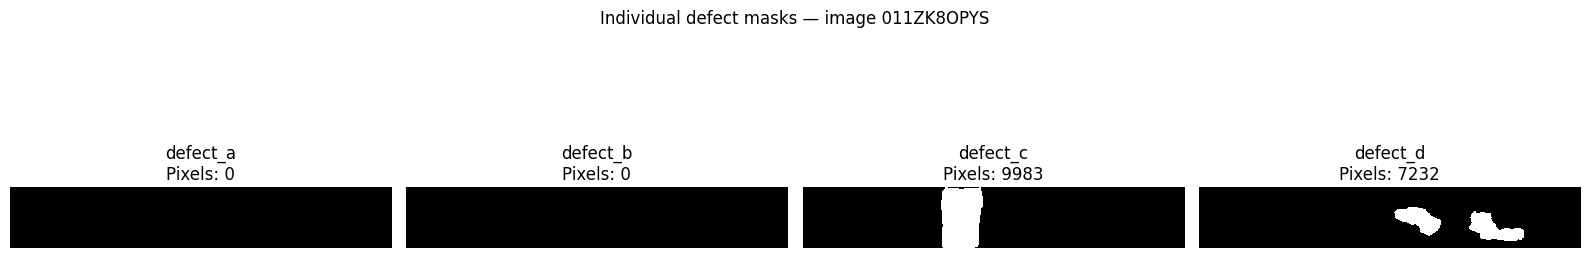

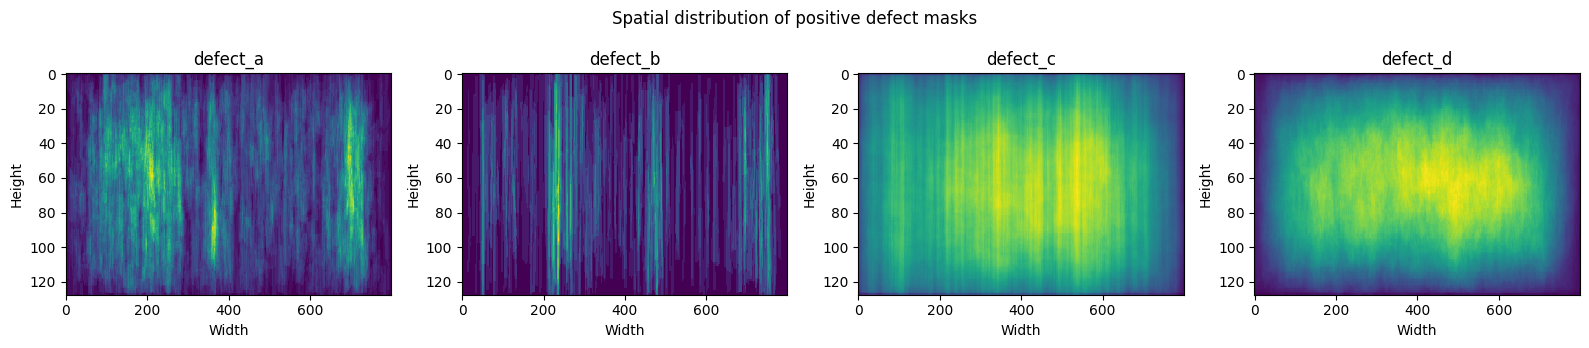

In [16]:

import matplotlib.pyplot as plt
import numpy as np

# Find an image containing at least two defect classes
multi_ids = (
    df.groupby("image_id")["has_defect"]
      .sum()
      .loc[lambda s: s > 1]
      .index
)

image_id = multi_ids[0]
group = df[df["image_id"] == image_id]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (_, row) in zip(axes, group.iterrows()):
    mask = decode_rle(row["mask_rle"])
    ax.imshow(mask, cmap="gray", interpolation="nearest")
    ax.set_title(f'{row["defect_type"]}\nPixels: {int(mask.sum())}')
    ax.axis("off")

fig.suptitle(f"Individual defect masks — image {image_id}")
plt.tight_layout()
plt.show()

# Aggregate spatial heatmaps for each defect class
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))

for ax, defect_type in zip(
    axes, ["defect_a", "defect_b", "defect_c", "defect_d"]
):
    rows = df[
        (df["defect_type"] == defect_type) & df["has_defect"]
    ]

    heatmap = np.zeros((HEIGHT, WIDTH), dtype=np.float64)

    for rle in rows["mask_rle"]:
        heatmap += decode_rle(rle)

    ax.imshow(heatmap, aspect="auto", interpolation="nearest")
    ax.set_title(defect_type)
    ax.set_xlabel("Width")
    ax.set_ylabel("Height")

fig.suptitle("Spatial distribution of positive defect masks")
plt.tight_layout()
plt.show()


In [17]:

MAX_PIXELS = HEIGHT * WIDTH

rows_with_overrun = 0
runs_with_overrun = 0
max_end_index = 0
total_runs = 0

for rle in df["mask_rle"].dropna():
    rle = str(rle).strip()

    if not rle:
        continue

    values = np.fromstring(rle, sep=" ", dtype=np.int64)

    if len(values) % 2 != 0:
        print("WARNING: Odd number of RLE values:", rle[:100])
        continue

    starts = values[0::2]
    lengths = values[1::2]
    end_indices = starts + lengths - 1

    total_runs += len(end_indices)

    if len(end_indices) > 0:
        max_end_index = max(max_end_index, int(end_indices.max()))

    bad_runs = end_indices > MAX_PIXELS
    runs_with_overrun += int(bad_runs.sum())

    if bad_runs.any():
        rows_with_overrun += 1

print("Valid canvas pixel count:", MAX_PIXELS)
print("Total RLE runs checked:", total_runs)
print("Rows containing at least one overrun:", rows_with_overrun)
print("Individual runs exceeding the canvas:", runs_with_overrun)
print("Maximum RLE end index encountered:", max_end_index)


Valid canvas pixel count: 102400
Total RLE runs checked: 797406
Rows containing at least one overrun: 0
Individual runs exceeding the canvas: 0
Maximum RLE end index encountered: 102400


In [18]:

original_height, original_width = 128, 800
target_height, target_width = 256, 256

scale_y = target_height / original_height
scale_x = target_width / original_width
ratio = scale_y / scale_x

print("Vertical scale (sy):", scale_y)
print("Horizontal scale (sx):", scale_x)
print("Vertical stretch / horizontal compression ratio:", ratio)


Vertical scale (sy): 2.0
Horizontal scale (sx): 0.32
Vertical stretch / horizontal compression ratio: 6.25


In [19]:

import cv2
import numpy as np
from pathlib import Path

image_dir = base / "train"
classes = ["defect_a", "defect_b", "defect_c", "defect_d"]

# Accumulate intensity statistics without storing every pixel.
stats = {
    c: {
        "defect_n": 0, "defect_sum": 0.0, "defect_sq": 0.0,
        "bg_n": 0, "bg_sum": 0.0, "bg_sq": 0.0
    }
    for c in classes
}

missing_images = []
image_extensions = [".jpg", ".jpeg", ".png", ".tif", ".tiff"]

for image_id, group in df.groupby("image_id", sort=False):
    image_path = next(
        (image_dir / f"{image_id}{ext}"
         for ext in image_extensions
         if (image_dir / f"{image_id}{ext}").exists()),
        None
    )

    if image_path is None:
        missing_images.append(image_id)
        continue

    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if image is None or image.shape != (HEIGHT, WIDTH):
        print("WARNING: Could not load expected-size image:", image_path)
        continue

    for _, row in group.iterrows():
        c = row["defect_type"]
        mask = decode_rle(row["mask_rle"]).astype(bool)

        defect_pixels = image[mask].astype(np.float64)
        bg_pixels = image[~mask].astype(np.float64)

        s = stats[c]
        s["defect_n"] += defect_pixels.size
        s["defect_sum"] += defect_pixels.sum()
        s["defect_sq"] += np.square(defect_pixels).sum()
        s["bg_n"] += bg_pixels.size
        s["bg_sum"] += bg_pixels.sum()
        s["bg_sq"] += np.square(bg_pixels).sum()

def get_mean_var(n, total, total_sq):
    mean = total / n
    variance = max(0.0, (total_sq - total**2 / n) / (n - 1)) if n > 1 else 0.0
    return mean, variance

print("Missing image files:", len(missing_images))
print("\nCohen's d results (defect intensity minus background intensity):")

for c in classes:
    s = stats[c]
    n1, n2 = s["defect_n"], s["bg_n"]

    if n1 < 2 or n2 < 2:
        print(c, "Insufficient pixels")
        continue

    mean1, var1 = get_mean_var(n1, s["defect_sum"], s["defect_sq"])
    mean2, var2 = get_mean_var(n2, s["bg_sum"], s["bg_sq"])

    pooled_var = ((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2)
    pooled_std = np.sqrt(pooled_var)
    d = (mean1 - mean2) / pooled_std if pooled_std > 0 else np.nan

    print(
        f"{c}: d={d:.6f}, "
        f"defect_mean={mean1:.3f}, background_mean={mean2:.3f}"
    )


Missing image files: 0

Cohen's d results (defect intensity minus background intensity):
defect_a: d=0.176553, defect_mean=96.957, background_mean=88.474
defect_b: d=0.111320, defect_mean=93.828, background_mean=88.479
defect_c: d=0.383041, defect_mean=106.499, background_mean=88.121
defect_d: d=0.007413, defect_mean=88.833, background_mean=88.476


In [20]:
def dice_score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=bool)
    y_pred = np.asarray(y_pred, dtype=bool)

    if y_true.sum() == 0 and y_pred.sum() == 0:
        return 1.0

    intersection = np.logical_and(y_true, y_pred).sum()
    return 2.0 * intersection / (y_true.sum() + y_pred.sum())

empty_gt = np.zeros((128, 800), dtype=bool)

# Model 1 predicts an empty mask
pred_empty = np.zeros_like(empty_gt)

# Model 2 predicts two stray pixels
pred_two_pixels = np.zeros_like(empty_gt)
pred_two_pixels[10, 10] = True
pred_two_pixels[20, 20] = True

print("Model 1 Dice:", dice_score(empty_gt, pred_empty))
print("Model 2 Dice:", dice_score(empty_gt, pred_two_pixels))

Model 1 Dice: 1.0
Model 2 Dice: 0.0


In [21]:

import cv2
import numpy as np
import pandas as pd

# Collect ground-truth connected-component areas for each defect class.
component_areas = {name: [] for name in ["defect_a", "defect_b",
                                         "defect_c", "defect_d"]}
total_gt_pixels = {name: 0 for name in component_areas}

for _, row in df.iterrows():
    defect = row["defect_type"]
    mask = decode_rle(row["mask_rle"])

    total_gt_pixels[defect] += int(mask.sum())

    if mask.sum() == 0:
        continue

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=8
    )

    # Label 0 is the background; process labels 1 onward.
    areas = stats[1:, cv2.CC_STAT_AREA]
    component_areas[defect].extend(areas.tolist())

# Q10: smallest component for defect_b
area_min_b = min(component_areas["defect_b"])

# Pixel-loss percentage for components strictly smaller than N.
def lost_pixel_percentage(defect, threshold):
    areas = np.asarray(component_areas[defect], dtype=np.int64)
    lost_pixels = areas[areas < threshold].sum()
    total_pixels = total_gt_pixels[defect]
    return 100.0 * lost_pixels / total_pixels

lost_b_50 = lost_pixel_percentage("defect_b", 50)
lost_a_200 = lost_pixel_percentage("defect_a", 200)

print("Smallest defect_b component area:", area_min_b)
print(f"defect_b pixels lost at N=50: {lost_b_50:.4f}%")
print(f"defect_a pixels lost at N=200: {lost_a_200:.4f}%")


Smallest defect_b component area: 93
defect_b pixels lost at N=50: 0.0000%
defect_a pixels lost at N=200: 15.2171%


In [22]:

from pathlib import Path
import pandas as pd

root = Path("/kaggle/input")

sample_files = list(root.rglob("sample_submission.csv"))
train_files = list(root.rglob("train.csv"))
test_dirs = [
    path for path in root.rglob("test")
    if path.is_dir()
]

print("SAMPLE SUBMISSION FILES")
for path in sample_files:
    print(path)

print("\nTRAIN ANNOTATION FILES")
for path in train_files:
    print(path)

print("\nTEST IMAGE DIRECTORIES")
for directory in test_dirs:
    count = sum(
        1 for path in directory.rglob("*")
        if path.is_file()
        and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    print(f"{directory} | images: {count}")

if not sample_files:
    raise FileNotFoundError(
        "sample_submission.csv not found under /kaggle/input"
    )

sample = pd.read_csv(
    sample_files[0],
    keep_default_na=False
)

print("\nSAMPLE SUBMISSION SHAPE:", sample.shape)
print("COLUMNS:", sample.columns.tolist())
print(sample.head(8).to_string(index=False))


SAMPLE SUBMISSION FILES
/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv

TRAIN ANNOTATION FILES
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv

TEST IMAGE DIRECTORIES
/kaggle/input/competitions/industrial-surface-defect-detection/public/test | images: 3000

SAMPLE SUBMISSION SHAPE: (12000, 4)
COLUMNS: ['ID', 'image_id', 'defect_type', 'mask_rle']
 ID   image_id defect_type mask_rle
  1 WAFNKCRR7Q    defect_a         
  2 WAFNKCRR7Q    defect_b         
  3 WAFNKCRR7Q    defect_c         
  4 WAFNKCRR7Q    defect_d         
  5 YZXKEWSUDD    defect_a         
  6 YZXKEWSUDD    defect_b         
  7 YZXKEWSUDD    defect_c         
  8 YZXKEWSUDD    defect_d         


In [23]:
from pathlib import Path

for name in ["best.pt", "model_config.json"]:
    matches = list(Path("/kaggle/input").rglob(name))
    print(f"\n{name}:")
    if matches:
        for path in matches:
            print(f"FOUND: {path} ({path.stat().st_size:,} bytes)")
    else:
        print("NOT FOUND")


best.pt:
FOUND: /kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/best.pt (97,880,383 bytes)

model_config.json:
FOUND: /kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/model_config.json (813 bytes)


In [24]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [25]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image

if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "segmentation-models-pytorch"
    ])

import segmentation_models_pytorch as smp

MODEL_ROOT = Path("/kaggle/input/models")
TEST_DIR = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public/test"
)
SAMPLE_PATH = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public/sample_submission.csv"
)

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800

checkpoint_matches = list(MODEL_ROOT.rglob("best.pt"))
if len(checkpoint_matches) != 1:
    raise RuntimeError(
        f"Expected one attached checkpoint, found {len(checkpoint_matches)}"
    )

CHECKPOINT_PATH = checkpoint_matches[0]
CONFIG_PATH = CHECKPOINT_PATH.parent / "model_config.json"

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Missing model config: {CONFIG_PATH}")

with CONFIG_PATH.open() as f:
    model_config = json.load(f)

if model_config["class_order"] != CLASSES:
    raise ValueError("Model class order does not match the expected order.")

if (model_config["height"], model_config["width"]) != (HEIGHT, WIDTH):
    raise ValueError("Model input dimensions do not match.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint size:", f"{CHECKPOINT_PATH.stat().st_size:,} bytes")
print("SMP version:", __import__("importlib.metadata").metadata.version(
    "segmentation-models-pytorch"
))

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=4,
    activation=None,
)

try:
    state_dict = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )
except TypeError:
    state_dict = torch.load(CHECKPOINT_PATH, map_location="cpu")

model.load_state_dict(state_dict, strict=True)
model = model.to(device).eval()

sample = pd.read_csv(SAMPLE_PATH, keep_default_na=False)
image_ids = sample["image_id"].drop_duplicates().head(4).tolist()
extensions = [".jpg", ".jpeg", ".png", ".tif", ".tiff"]

batch_images = []

for image_id in image_ids:
    image_path = next(
        (
            TEST_DIR / f"{image_id}{ext}"
            for ext in extensions
            if (TEST_DIR / f"{image_id}{ext}").is_file()
        ),
        None
    )

    if image_path is None:
        raise FileNotFoundError(f"Test image not found: {image_id}")

    with Image.open(image_path) as image:
        array = np.asarray(image.convert("L"), dtype=np.float32) / 255.0

    if array.shape != (HEIGHT, WIDTH):
        raise ValueError(
            f"Unexpected dimensions for {image_id}: {array.shape}"
        )

    array = (array - array.mean()) / max(float(array.std()), 0.05)
    batch_images.append(array)

batch = torch.from_numpy(
    np.stack(batch_images)[:, None].copy()
).to(device)

with torch.inference_mode():
    probabilities = torch.sigmoid(model(batch)).cpu().numpy()

if probabilities.shape != (len(image_ids), 4, HEIGHT, WIDTH):
    raise RuntimeError(f"Unexpected output shape: {probabilities.shape}")

if not np.isfinite(probabilities).all():
    raise RuntimeError("Predictions contain NaN or infinite values.")

print("\nInference smoke test passed.")
print("Input tensor shape:", tuple(batch.shape))
print("Output tensor shape:", probabilities.shape)
print("Probability range:", float(probabilities.min()), float(probabilities.max()))

for index, image_id in enumerate(image_ids):
    print(f"\nImage: {image_id}")
    for class_index, defect_type in enumerate(CLASSES):
        fraction = float(
            (probabilities[index, class_index] >= 0.5).mean()
        )
        print(f"  {defect_type}: predicted pixel fraction = {fraction:.6f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.6/154.6 kB 3.2 MB/s eta 0:00:00
Device: cuda
GPU: Tesla T4
Checkpoint: /kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2/best.pt
Checkpoint size: 97,880,383 bytes
SMP version: 0.6.0

Inference smoke test passed.
Input tensor shape: (4, 1, 128, 800)
Output tensor shape: (4, 4, 128, 800)
Probability range: 1.274132355177926e-08 0.9951377511024475

Image: WAFNKCRR7Q
  defect_a: predicted pixel fraction = 0.000000
  defect_b: predicted pixel fraction = 0.000000
  defect_c: predicted pixel fraction = 0.000000
  defect_d: predicted pixel fraction = 0.000000

Image: YZXKEWSUDD
  defect_a: predicted pixel fraction = 0.000137
  defect_b: predicted pixel fraction = 0.000078
  defect_c: predicted pixel fraction = 0.003330
  defect_d: predicted pixel fraction = 0.000000

Image: 0ATN06ZB48
  defect_a: predicted pixel fraction = 0.012666
  defect_b: predicted pixel fraction = 0.011279
  defect_c: predic

In [26]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
import segmentation_models_pytorch as smp

ROOT = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
TEST_DIR = ROOT / "test"
SAMPLE_PATH = ROOT / "sample_submission.csv"
MODEL_DIR = Path("/kaggle/input/models/shrutikarthikeyan/surfaceguard-ai-q12-resnet34-unet/pytorch/baseline-128x800/2")
CHECKPOINT = MODEL_DIR / "best.pt"
CONFIG_PATH = MODEL_DIR / "model_config.json"
OUTPUT_PATH = Path("/kaggle/working/submission_resnet34_unet_t050.csv")

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800
THRESHOLD = 0.35
BATCH_SIZE = 8
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for path in [TEST_DIR, SAMPLE_PATH, CHECKPOINT, CONFIG_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required path not found: {path}")

with CONFIG_PATH.open() as f:
    config = json.load(f)

if config["class_order"] != CLASSES:
    raise ValueError("Checkpoint class order does not match the submission classes.")

if (config["height"], config["width"]) != (HEIGHT, WIDTH):
    raise ValueError("Checkpoint dimensions do not match the expected image size.")

sample = pd.read_csv(SAMPLE_PATH, keep_default_na=False)
required_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if sample.columns.tolist() != required_columns:
    raise ValueError(f"Unexpected submission columns: {sample.columns.tolist()}")

if len(sample) != 12000 or sample["image_id"].nunique() != 3000:
    raise ValueError("Unexpected sample submission dimensions.")

if set(sample["defect_type"].unique()) != set(CLASSES):
    raise ValueError("Sample submission defect classes do not match.")

def encode_rle(mask):
    pixels = np.asarray(mask, dtype=np.uint8).reshape(-1, order="F")
    padded = np.pad(pixels, (1, 1))
    changes = np.flatnonzero(padded[1:] != padded[:-1]) + 1

    if changes.size == 0:
        return ""

    runs = changes.copy()
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs.tolist()))

def decode_rle(rle, shape):
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)

    if not rle.strip():
        return flat.reshape(shape, order="F")

    values = np.fromstring(rle, sep=" ", dtype=np.int64)

    if len(values) % 2:
        raise ValueError("RLE must contain start-length pairs.")

    starts = values[0::2] - 1
    lengths = values[1::2]

    if np.any(starts < 0) or np.any(lengths <= 0):
        raise ValueError("Invalid RLE start or length.")

    for start, length in zip(starts, lengths):
        end = start + length
        if end > flat.size:
            raise ValueError("RLE exceeds the image dimensions.")
        flat[start:end] = 1

    return flat.reshape(shape, order="F")

toy = np.zeros((7, 9), dtype=np.uint8)
toy[1:4, 2] = 1
toy[5, 7:9] = 1

if not np.array_equal(toy, decode_rle(encode_rle(toy), toy.shape)):
    raise RuntimeError("RLE round-trip test failed.")

extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
image_paths = {
    path.stem: path
    for path in TEST_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in extensions
}

image_ids = sample["image_id"].drop_duplicates().tolist()
missing_ids = [image_id for image_id in image_ids if image_id not in image_paths]

if missing_ids:
    raise FileNotFoundError(
        f"{len(missing_ids)} test images could not be located. "
        f"Examples: {missing_ids[:5]}"
    )

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=4,
    activation=None,
)

try:
    state_dict = torch.load(
        CHECKPOINT,
        map_location="cpu",
        weights_only=True,
    )
except TypeError:
    state_dict = torch.load(CHECKPOINT, map_location="cpu")

model.load_state_dict(state_dict, strict=True)
model.to(DEVICE).eval()

predictions = {}
positive_pixels = np.zeros(4, dtype=np.int64)
empty_masks = 0

for start in range(0, len(image_ids), BATCH_SIZE):
    batch_ids = image_ids[start:start + BATCH_SIZE]
    arrays = []

    for image_id in batch_ids:
        with Image.open(image_paths[image_id]) as image:
            array = np.asarray(image.convert("L"), dtype=np.float32) / 255.0

        if array.shape != (HEIGHT, WIDTH):
            raise ValueError(
                f"{image_id}: expected {(HEIGHT, WIDTH)}, got {array.shape}"
            )

        array = (array - array.mean()) / max(float(array.std()), 0.05)
        arrays.append(array)

    tensor = torch.from_numpy(
        np.stack(arrays)[:, None].copy()
    ).to(DEVICE)

    with torch.inference_mode():
        probabilities = torch.sigmoid(model(tensor)).cpu().numpy()

    if not np.isfinite(probabilities).all():
        raise RuntimeError("Model produced non-finite predictions.")

    for i, image_id in enumerate(batch_ids):
        for class_index, defect_type in enumerate(CLASSES):
            mask = probabilities[i, class_index] >= THRESHOLD
            positive_pixels[class_index] += int(mask.sum())

            if not mask.any():
                empty_masks += 1

            predictions[(image_id, defect_type)] = encode_rle(mask)

    completed = min(start + len(batch_ids), len(image_ids))

    if completed % 400 == 0 or completed == len(image_ids):
        print(f"Processed {completed}/{len(image_ids)} images")

if len(predictions) != len(sample):
    raise RuntimeError(
        f"Expected {len(sample)} predictions; got {len(predictions)}."
    )

submission = sample.copy()
submission["mask_rle"] = [
    predictions[(image_id, defect_type)]
    for image_id, defect_type in zip(
        sample["image_id"], sample["defect_type"]
    )
]

if submission.isna().any().any():
    raise ValueError("Submission contains missing values.")

if submission[["image_id", "defect_type"]].duplicated().any():
    raise ValueError("Duplicate image/category combinations found.")

submission.to_csv(OUTPUT_PATH, index=False)

check = pd.read_csv(OUTPUT_PATH, keep_default_na=False)

if not check.equals(submission):
    raise RuntimeError("Saved submission does not match the generated dataframe.")

print("\nSubmission created and verified.")
print("Output:", OUTPUT_PATH)
print("Shape:", check.shape)
print("Columns:", check.columns.tolist())
print("Unique images:", check["image_id"].nunique())
print("Threshold:", THRESHOLD)
print("Empty masks:", empty_masks, "of", len(check))
print("Predicted foreground pixels by class:", dict(zip(CLASSES, positive_pixels)))
print(check.head(8).to_string(index=False))

Processed 400/3000 images
Processed 800/3000 images
Processed 1200/3000 images
Processed 1600/3000 images
Processed 2000/3000 images
Processed 2400/3000 images
Processed 2800/3000 images
Processed 3000/3000 images

Submission created and verified.
Output: /kaggle/working/submission_resnet34_unet_t050.csv
Shape: (12000, 4)
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Unique images: 3000
Threshold: 0.35
Empty masks: 2636 of 12000
Predicted foreground pixels by class: {'defect_a': np.int64(1688526), 'defect_b': np.int64(1588546), 'defect_c': np.int64(4821976), 'defect_d': np.int64(11738910)}
 ID   image_id defect_type                                                                                                                                                                                                                                                                                                              mask_rle
  1 WAFNKCRR7Q    defect_a                               

In [27]:
from pathlib import Path
import pandas as pd

root = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
working = Path("/kaggle/working")

sample_path = root / "sample_submission.csv"
model_path = working / "submission_resnet34_unet_t050.csv"
final_path = working / "submission.csv"

if not model_path.is_file():
    raise FileNotFoundError(
        f"Trained-model predictions not found: {model_path}"
    )

sample = pd.read_csv(sample_path, keep_default_na=False)
predictions = pd.read_csv(model_path, keep_default_na=False)

expected_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if predictions.columns.tolist() != expected_columns:
    raise ValueError("Trained-model submission has incorrect columns.")

if len(predictions) != 12000 or len(sample) != 12000:
    raise ValueError("Unexpected submission row count.")

if not predictions[expected_columns[:3]].equals(sample[expected_columns[:3]]):
    raise ValueError("Prediction IDs or row order do not match the sample.")

nonempty = predictions["mask_rle"].astype(str).str.strip().ne("").sum()

if nonempty == 0:
    raise ValueError(
        "Every predicted mask is empty. Do not submit this file yet."
    )

predictions.to_csv(final_path, index=False)

verified = pd.read_csv(final_path, keep_default_na=False)

if not verified.equals(predictions):
    raise RuntimeError("Final submission verification failed.")

print("Final trained-model submission created.")
print("File:", final_path)
print("Rows:", len(verified))
print("Non-empty predicted masks:", nonempty)
print("Empty predicted masks:", len(verified) - nonempty)
print("Columns:", verified.columns.tolist())
print(verified.head(8).to_string(index=False))

Final trained-model submission created.
File: /kaggle/working/submission.csv
Rows: 12000
Non-empty predicted masks: 9364
Empty predicted masks: 2636
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
 ID   image_id defect_type                                                                                                                                                                                                                                                                                                              mask_rle
  1 WAFNKCRR7Q    defect_a                                                                                                                                                                                                                                                                                                                      
  2 WAFNKCRR7Q    defect_b                                                                                                

In [28]:
from pathlib import Path
import csv
import pandas as pd

root = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
sample_path = root / "sample_submission.csv"

source_path = Path("/kaggle/working/submission_resnet34_unet_t050.csv")
output_path = Path("/kaggle/working/submission.csv")

if not source_path.is_file():
    raise FileNotFoundError(f"Trained-model submission not found: {source_path}")

sample = pd.read_csv(sample_path, keep_default_na=False)
submission = pd.read_csv(source_path, keep_default_na=False)

expected_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if submission.columns.tolist() != expected_columns:
    raise ValueError(f"Unexpected columns: {submission.columns.tolist()}")

if len(submission) != len(sample):
    raise ValueError("Submission row count does not match the sample.")

if not submission[["ID", "image_id", "defect_type"]].equals(
    sample[["ID", "image_id", "defect_type"]]
):
    raise ValueError("Submission IDs or row order differ from the sample.")

empty_mask = submission["mask_rle"].astype(str).str.strip().eq("")
submission.loc[empty_mask, "mask_rle"] = " "

submission.to_csv(
    output_path,
    index=False,
    quoting=csv.QUOTE_ALL,
)

verified = pd.read_csv(output_path)

if verified.isna().any().any():
    raise ValueError(
        f"Null values remain:\n{verified.isna().sum()}"
    )

if len(verified) != 12000:
    raise ValueError("Expected exactly 12,000 prediction rows.")

print("Submission validated successfully.")
print("File:", output_path)
print("Rows:", len(verified))
print("Null values:", int(verified.isna().sum().sum()))
print(
    "Empty masks represented by spaces:",
    int(verified["mask_rle"].astype(str).str.strip().eq("").sum())
)
print("Columns:", verified.columns.tolist())

Submission validated successfully.
File: /kaggle/working/submission.csv
Rows: 12000
Null values: 0
Empty masks represented by spaces: 2636
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']


In [29]:

# SurfaceGuard AI — Kaggle GPU training setup

from pathlib import Path
import random
import json
import importlib.util
import subprocess
import sys

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# Install segmentation library only if needed
if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "segmentation-models-pytorch"
    ])

import segmentation_models_pytorch as smp

# Competition dataset paths
DATA_ROOT = Path(
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public"
)

OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Project configuration — matches the existing model
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800
VAL_FRACTION = 0.20
SEED = 42
EPOCHS = 10
BATCH_SIZE = 8
ENCODER = "resnet34"
ENCODER_WEIGHTS = "imagenet"

THRESHOLDS = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50, 0.55,
    0.60, 0.65, 0.70, 0.75, 0.80,
    0.85, 0.90
]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for path in [
    DATA_ROOT / "train.csv",
    DATA_ROOT / "train",
    DATA_ROOT / "test",
]:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

assert DEVICE.type == "cuda", "GPU is not enabled in Kaggle settings."
assert (DATA_ROOT / "train.csv").is_file(), "Training CSV not found."
assert (DATA_ROOT / "train").is_dir(), "Training image folder not found."


Device: cuda
GPU: Tesla T4
FOUND: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
FOUND: /kaggle/input/competitions/industrial-surface-defect-detection/public/train
FOUND: /kaggle/input/competitions/industrial-surface-defect-detection/public/test


In [30]:

# Step 2B: Load annotations and create a reproducible split

annotations = pd.read_csv(
    DATA_ROOT / "train.csv",
    dtype=str,
    keep_default_na=False
)

required = {"image_id", "defect_type", "mask_rle", "height", "width"}

if not required.issubset(annotations.columns):
    raise ValueError(
        f"Missing CSV columns: {required - set(annotations.columns)}"
    )

if set(annotations["defect_type"]) != set(CLASSES):
    raise ValueError("Unexpected defect classes in train.csv")

if annotations.duplicated(["image_id", "defect_type"]).any():
    raise ValueError("Duplicate image-class rows found")

if not (annotations.groupby("image_id").size() == len(CLASSES)).all():
    raise ValueError("Each image must have one row per defect class")

if not (
    (annotations["height"].astype(int) == HEIGHT)
    & (annotations["width"].astype(int) == WIDTH)
).all():
    raise ValueError("Expected image dimensions: 128 × 800")

annotations["mask_rle"] = annotations["mask_rle"].str.strip()

rle_table = (
    annotations.pivot(
        index="image_id",
        columns="defect_type",
        values="mask_rle"
    )
    .reindex(columns=CLASSES)
    .sort_index()
)

presence = rle_table.ne("")

def combination_string(row):
    active = [name for name in CLASSES if row[name]]
    return "+".join(active) if active else "clean"

image_table = presence.copy()
image_table["label_combo"] = presence.apply(
    combination_string, axis=1
)

combination_counts = image_table["label_combo"].value_counts()

print("Annotation rows:", len(annotations))
print("Unique training images:", len(image_table))
print("\nClass presence:")
print(presence.sum().to_string())
print("\nLabel combinations:")
print(combination_counts.to_string())

if combination_counts.min() < 2:
    raise ValueError(
        "At least one label combination occurs fewer than twice. "
        "We need to handle that before splitting."
    )

train_ids, val_ids = train_test_split(
    image_table.index.to_numpy(),
    test_size=VAL_FRACTION,
    random_state=SEED,
    stratify=image_table["label_combo"].to_numpy()
)

assert not set(train_ids) & set(val_ids)
assert set(train_ids) | set(val_ids) == set(image_table.index)

split_table = image_table[["label_combo"]].copy()
split_table["partition"] = "train"
split_table.loc[val_ids, "partition"] = "validation"

split_table.to_csv(
    OUTPUT_DIR / "holdout.csv",
    index_label="image_id"
)

print("\nTraining images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Saved split:", OUTPUT_DIR / "holdout.csv")


Annotation rows: 45572
Unique training images: 11393

Class presence:
defect_type
defect_a    1081
defect_b     313
defect_c    4100
defect_d    1707

Label combinations:
label_combo
clean                         5516
defect_c                      3105
defect_d                       822
defect_a                       601
defect_c+defect_d              598
defect_a+defect_c              215
defect_b                       151
defect_a+defect_d              136
defect_a+defect_c+defect_d      87
defect_b+defect_c               67
defect_b+defect_d               33
defect_a+defect_b               23
defect_b+defect_c+defect_d      20
defect_a+defect_b+defect_d      11
defect_a+defect_b+defect_c       8

Training images: 9114
Validation images: 2279
Saved split: /kaggle/working/surfaceguard_training/holdout.csv


In [31]:

# # Step 3 — Verify the split and image paths

# print("Training images:", len(train_df))
# print("Validation images:", len(val_df))

# print("\nTraining split preview:")
# display(train_df.head())

# print("\nValidation split preview:")
# display(val_df.head())

# # Check that train and validation images do not overlap
# train_ids = set(train_df["image_id"].astype(str))
# val_ids = set(val_df["image_id"].astype(str))

# print("\nOverlapping images:", len(train_ids & val_ids))
# assert len(train_ids & val_ids) == 0, "Data leakage: overlapping images!"

# # Check a few image paths
# for image_id in list(train_ids)[:5]:
#     matches = list((DATA_ROOT / "train").glob(f"{image_id}.*"))
#     print(image_id, "->", matches[0] if matches else "NOT FOUND")


In [32]:

# Step 3A — Inspect the saved split

holdout = pd.read_csv(
    OUTPUT_DIR / "holdout.csv",
    dtype=str,
    keep_default_na=False
)

print("Shape:", holdout.shape)
print("Columns:", holdout.columns.tolist())
display(holdout.head())

for col in holdout.columns:
    if "split" in col.lower():
        print(f"\nValues in {col}:")
        print(holdout[col].value_counts())


Shape: (11393, 3)
Columns: ['image_id', 'label_combo', 'partition']


,image_id,label_combo,partition
0,000HAM628W,defect_c,train
1,005VFS2MW4,defect_d,train
2,0070O9IJVX,defect_d,train
3,00761I10TU,defect_c,train
4,009DUJJXC1,clean,train


In [33]:

# Step 3B — Verify train/validation split

train_df = holdout[holdout["partition"] == "train"].copy()
val_df = holdout[holdout["partition"] == "validation"].copy()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining label combinations:")
print(train_df["label_combo"].value_counts())

print("\nValidation label combinations:")
print(val_df["label_combo"].value_counts())

# Verify no image occurs in both partitions
train_ids = set(train_df["image_id"])
val_ids = set(val_df["image_id"])

print("\nOverlapping images:", len(train_ids & val_ids))
assert len(train_ids & val_ids) == 0, "Train/validation overlap detected!"

# Check actual image filenames
image_dir = DATA_ROOT / "train"

for image_id in train_df["image_id"].head(5):
    matches = list(image_dir.glob(f"{image_id}.*"))
    print(image_id, "->", matches[0] if matches else "NOT FOUND")

assert len(train_df) > 0 and len(val_df) > 0


Training images: 9114
Validation images: 2279

Training label combinations:
label_combo
clean                         4413
defect_c                      2484
defect_d                       657
defect_a                       481
defect_c+defect_d              478
defect_a+defect_c              172
defect_b                       121
defect_a+defect_d              109
defect_a+defect_c+defect_d      70
defect_b+defect_c               54
defect_b+defect_d               26
defect_a+defect_b               18
defect_b+defect_c+defect_d      16
defect_a+defect_b+defect_d       9
defect_a+defect_b+defect_c       6
Name: count, dtype: int64

Validation label combinations:
label_combo
clean                         1103
defect_c                       621
defect_d                       165
defect_c+defect_d              120
defect_a                       120
defect_a+defect_c               43
defect_b                        30
defect_a+defect_d               27
defect_a+defect_c+defect_d      17
de

In [34]:

# Step 4 — Build image masks and PyTorch dataset

from collections import defaultdict

annotations = pd.read_csv(
    DATA_ROOT / "train.csv",
    dtype=str,
    keep_default_na=False
)

print("Annotation columns:", annotations.columns.tolist())

def decode_rle(rle, height=HEIGHT, width=WIDTH):
    """Decode a competition RLE mask into a 2D binary mask."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if not rle or not rle.strip():
        return mask.reshape(height, width)

    values = np.asarray(rle.split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start + length] = 1

    # RLE convention: column-major / Fortran order
    return mask.reshape((height, width), order="F")


# One binary mask per image and defect class
mask_lookup = defaultdict(
    lambda: np.zeros((len(CLASSES), HEIGHT, WIDTH), dtype=np.uint8)
)

for row in tqdm(annotations.itertuples(index=False),
                total=len(annotations),
                desc="Decoding masks"):
    image_id = str(row.image_id)
    defect_type = str(row.defect_type)
    rle = str(row.mask_rle)

    if defect_type not in CLASSES:
        continue

    class_idx = CLASSES.index(defect_type)
    decoded = decode_rle(rle)

    mask_lookup[image_id][class_idx] = np.maximum(
        mask_lookup[image_id][class_idx],
        decoded
    )

print("Images with decoded masks:", len(mask_lookup))
print("Mask shape:", next(iter(mask_lookup.values())).shape)
print("Classes:", CLASSES)


Annotation columns: ['image_id', 'defect_type', 'mask_rle', 'width', 'height']


Decoding masks:   0%|          | 0/45572 [00:00<?, ?it/s]

Images with decoded masks: 11393
Mask shape: (4, 128, 800)
Classes: ['defect_a', 'defect_b', 'defect_c', 'defect_d']


In [35]:

# Step 5 — Create the PyTorch dataset

class SurfaceDefectDataset(Dataset):
    def __init__(self, dataframe, image_dir, mask_lookup):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.mask_lookup = mask_lookup

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_id = str(row["image_id"])

        image_path = self.image_dir / f"{image_id}.jpg"

        image = Image.open(image_path).convert("L")
        image = image.resize((WIDTH, HEIGHT), Image.Resampling.BILINEAR)

        image = np.asarray(image, dtype=np.float32) / 255.0

        # Match the grayscale normalization used in the baseline
        mean = image.mean()
        std = max(float(image.std()), 0.05)
        image = (image - mean) / std

        image = torch.from_numpy(image.copy()).unsqueeze(0)

        mask = self.mask_lookup[image_id].astype(np.float32)
        mask = torch.from_numpy(mask.copy())

        return image, mask


train_dataset = SurfaceDefectDataset(
    train_df, DATA_ROOT / "train", mask_lookup
)

val_dataset = SurfaceDefectDataset(
    val_df, DATA_ROOT / "train", mask_lookup
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

# Inspect one sample
sample_image, sample_mask = train_dataset[0]

print("Image tensor shape:", sample_image.shape)
print("Mask tensor shape:", sample_mask.shape)
print("Image dtype:", sample_image.dtype)
print("Mask dtype:", sample_mask.dtype)
print("Mask values:", torch.unique(sample_mask))


Training samples: 9114
Validation samples: 2279
Image tensor shape: torch.Size([1, 128, 800])
Mask tensor shape: torch.Size([4, 128, 800])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask values: tensor([0., 1.])


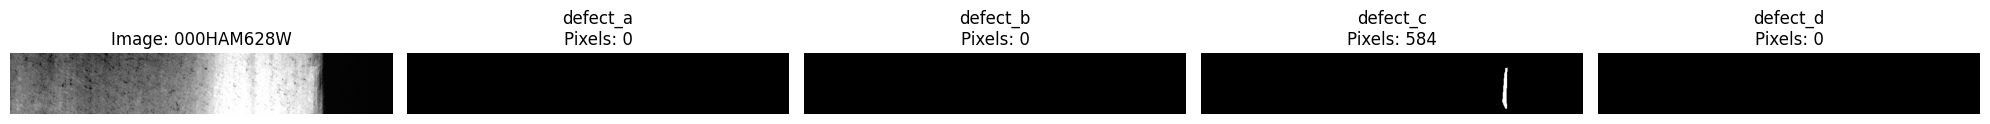

In [36]:

# Step 6 — Visually inspect image and decoded masks

sample_image, sample_mask = train_dataset[0]
image_id = str(train_df.iloc[0]["image_id"])

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(sample_image.squeeze(0).numpy(), cmap="gray")
axes[0].set_title(f"Image: {image_id}")

for i, class_name in enumerate(CLASSES):
    axes[i + 1].imshow(
        sample_mask[i].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i + 1].set_title(
        f"{class_name}\nPixels: {int(sample_mask[i].sum())}"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


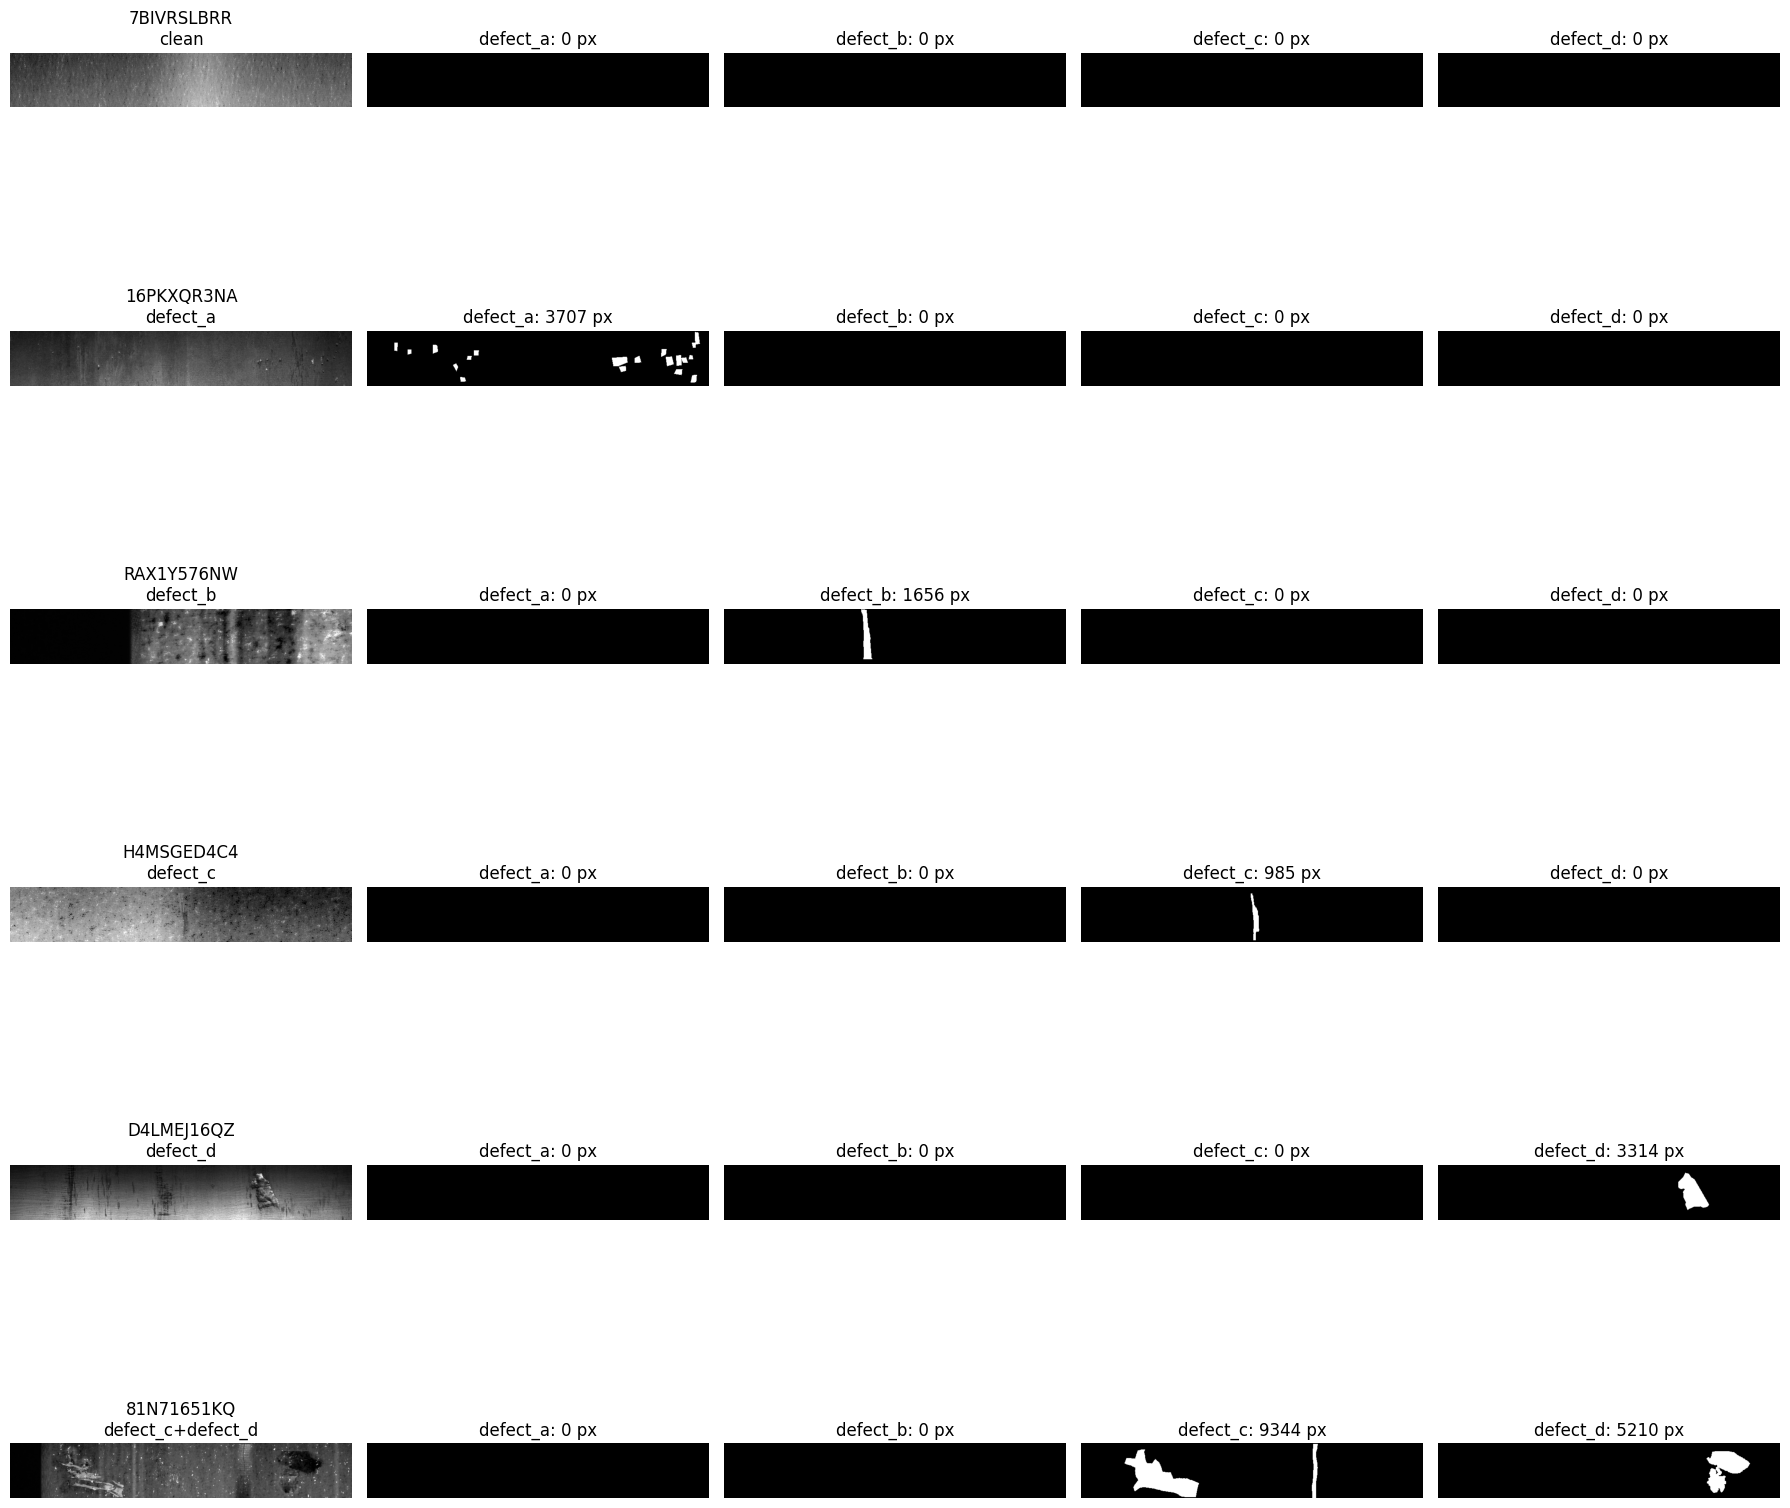

In [37]:

# Step 7 — Inspect different label combinations

import random

random.seed(SEED)

sample_indices = []

# Include a clean image and examples of different defect combinations
for combo in [
    "clean",
    "defect_a",
    "defect_b",
    "defect_c",
    "defect_d",
    "defect_c+defect_d",
]:
    candidates = train_df.index[
        train_df["label_combo"] == combo
    ].tolist()

    if candidates:
        sample_indices.append(random.choice(candidates))

fig, axes = plt.subplots(
    len(sample_indices), 5,
    figsize=(18, 3 * len(sample_indices)),
    squeeze=False
)

for row_idx, df_idx in enumerate(sample_indices):
    image_id = str(train_df.loc[df_idx, "image_id"])
    image_tensor, mask_tensor = train_dataset[
        train_df.index.get_loc(df_idx)
    ]

    axes[row_idx, 0].imshow(
        image_tensor.squeeze(0).numpy(), cmap="gray"
    )
    axes[row_idx, 0].set_title(
        f"{image_id}\n{train_df.loc[df_idx, 'label_combo']}"
    )

    for class_idx, class_name in enumerate(CLASSES):
        axes[row_idx, class_idx + 1].imshow(
            mask_tensor[class_idx].numpy(),
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row_idx, class_idx + 1].set_title(
            f"{class_name}: {int(mask_tensor[class_idx].sum())} px"
        )

    for ax in axes[row_idx]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [38]:

# Step 8 — Create DataLoaders

BATCH_SIZE = 8
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Test one batch without training
images, masks = next(iter(train_loader))

print("Batch images:", images.shape)
print("Batch masks:", masks.shape)
print("Device:", DEVICE)
print("GPU available:", torch.cuda.is_available())

assert images.shape[1:] == (1, HEIGHT, WIDTH)
assert masks.shape[1:] == (len(CLASSES), HEIGHT, WIDTH)

del images, masks
print("DataLoader test passed.")


Training batches: 1140
Validation batches: 285
Batch images: torch.Size([8, 1, 128, 800])
Batch masks: torch.Size([8, 4, 128, 800])
Device: cuda
GPU available: True
DataLoader test passed.


In [39]:

# Step 9 — Create the segmentation model

model = smp.Unet(
    encoder_name=ENCODER,
    encoder_weights=ENCODER_WEIGHTS,
    in_channels=1,
    classes=len(CLASSES),
    activation=None,
)

model = model.to(DEVICE)

# Binary segmentation loss for four independent defect classes
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

print("Model:", ENCODER, "U-Net")
print("Output classes:", len(CLASSES))
print("Device:", next(model.parameters()).device)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: resnet34 U-Net
Output classes: 4
Device: cuda:0
Parameters: 24,430,532


In [40]:

# Step 10 — Training loop with validation and best checkpoint saving

import time
from tqdm.auto import tqdm

EPOCHS = 5
best_val_dice = -1.0
history = []

checkpoint_path = OUTPUT_DIR / "best.pt"

# Mixed precision for faster GPU training
scaler = torch.amp.GradScaler("cuda")

def dice_per_class_from_logits(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()

    intersection = (preds * targets).sum(dim=(0, 2, 3))
    denominator = preds.sum(dim=(0, 2, 3)) + targets.sum(dim=(0, 2, 3))

    return (2 * intersection + eps) / (denominator + eps)


for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    # Training
    model.train()
    train_loss_sum = 0.0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} - train")

    for images, masks in train_bar:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_sum += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = train_loss_sum / len(train_loader)

    # Validation
    model.eval()
    val_loss_sum = 0.0
    dice_sum = torch.zeros(len(CLASSES), device=DEVICE)

    with torch.no_grad():
        for images, masks in tqdm(
            val_loader, desc=f"Epoch {epoch}/{EPOCHS} - val"
        ):
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)
                loss = criterion(logits, masks)

            val_loss_sum += loss.item()
            dice_sum += dice_per_class_from_logits(
                logits.float(), masks, threshold=0.5
            )

    avg_val_loss = val_loss_sum / len(val_loader)
    class_dice = (dice_sum / len(val_loader)).cpu().numpy()
    mean_dice = float(class_dice.mean())

    epoch_info = {
        "epoch": epoch,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "mean_dice": mean_dice,
    }
    history.append(epoch_info)

    print(f"\nEpoch {epoch}/{EPOCHS}")
    print(f"Train loss: {avg_train_loss:.5f}")
    print(f"Validation loss: {avg_val_loss:.5f}")
    print(f"Mean class Dice @ 0.5: {mean_dice:.5f}")

    for class_name, score in zip(CLASSES, class_dice):
        print(f"  {class_name}: {score:.5f}")

    if mean_dice > best_val_dice:
        best_val_dice = mean_dice
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "epoch": epoch,
                "mean_dice": mean_dice,
                "classes": CLASSES,
                "height": HEIGHT,
                "width": WIDTH,
                "encoder": ENCODER,
            },
            checkpoint_path,
        )
        print("Saved best checkpoint:", checkpoint_path)

    print(f"Epoch time: {(time.time() - start_time) / 60:.1f} minutes")

print("\nTraining finished.")
print("Best validation mean Dice:", best_val_dice)
print("Checkpoint exists:", checkpoint_path.exists())


Epoch 1/5 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 1/5 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 1/5
Train loss: 0.17355
Validation loss: 0.03800
Mean class Dice @ 0.5: 0.38440
  defect_a: 0.44211
  defect_b: 0.78947
  defect_c: 0.02179
  defect_d: 0.28421
Saved best checkpoint: /kaggle/working/surfaceguard_training/best.pt
Epoch time: 2.3 minutes


Epoch 2/5 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 2/5 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 2/5
Train loss: 0.02914
Validation loss: 0.02422
Mean class Dice @ 0.5: 0.50409
  defect_a: 0.44211
  defect_b: 0.78947
  defect_c: 0.48654
  defect_d: 0.29825
Saved best checkpoint: /kaggle/working/surfaceguard_training/best.pt
Epoch time: 2.3 minutes


... (6 outputs left out)


Epoch 4/5
Train loss: 0.01799
Validation loss: 0.01810
Mean class Dice @ 0.5: 0.53661
  defect_a: 0.44211
  defect_b: 0.78947
  defect_c: 0.36182
  defect_d: 0.55303
Saved best checkpoint: /kaggle/working/surfaceguard_training/best.pt
Epoch time: 2.7 minutes


Epoch 5/5 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 5/5 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 5/5
Train loss: 0.01570
Validation loss: 0.01553
Mean class Dice @ 0.5: 0.57262
  defect_a: 0.44211
  defect_b: 0.78947
  defect_c: 0.45886
  defect_d: 0.60004
Saved best checkpoint: /kaggle/working/surfaceguard_training/best.pt
Epoch time: 2.3 minutes

Training finished.
Best validation mean Dice: 0.5726204514503479
Checkpoint exists: True


In [41]:

# Step 11 — Restore the best validation checkpoint

checkpoint = torch.load(
    OUTPUT_DIR / "best.pt",
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Saved validation Dice:", checkpoint["mean_dice"])
print("Model device:", next(model.parameters()).device)


Best checkpoint epoch: 5
Saved validation Dice: 0.5726204514503479
Model device: cuda:0


In [42]:

# Step 12 — Threshold sweep on validation data

thresholds = THRESHOLDS

num_classes = len(CLASSES)
intersections = torch.zeros(
    len(thresholds), num_classes, dtype=torch.float64
)
unions = torch.zeros_like(intersections)

model.eval()

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Threshold sweep"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        probs = torch.sigmoid(logits.float())
        targets = masks.bool()

        for ti, threshold in enumerate(thresholds):
            preds = probs >= threshold

            intersection = (preds & targets).sum(dim=(0, 2, 3))
            union = (preds | targets).sum(dim=(0, 2, 3))

            intersections[ti] += intersection.cpu().double()
            unions[ti] += union.cpu().double()

# Avoid division by zero for classes with no positive pixels
ious = intersections / unions.clamp_min(1)

print("Validation IoU by threshold:")
for ti, threshold in enumerate(thresholds):
    print(f"{threshold:.2f}: mean IoU = {ious[ti].mean().item():.5f}")

best_indices = ious.argmax(dim=0)
best_thresholds = [
    thresholds[idx.item()] for idx in best_indices
]

print("\nBest threshold per class:")
for i, class_name in enumerate(CLASSES):
    print(
        f"{class_name}: threshold={best_thresholds[i]:.2f}, "
        f"IoU={ious[best_indices[i], i].item():.5f}"
    )

print("\nMean IoU using per-class best thresholds:")
print(
    ious[best_indices, torch.arange(num_classes)].mean().item()
)


Threshold sweep:   0%|          | 0/285 [00:00<?, ?it/s]

Validation IoU by threshold:
0.10: mean IoU = 0.25034
0.15: mean IoU = 0.25562
0.20: mean IoU = 0.25851
0.25: mean IoU = 0.25714
0.30: mean IoU = 0.25199
0.35: mean IoU = 0.24561
0.40: mean IoU = 0.23900
0.45: mean IoU = 0.23202
0.50: mean IoU = 0.22447
0.55: mean IoU = 0.21600
0.60: mean IoU = 0.20599
0.65: mean IoU = 0.19258
0.70: mean IoU = 0.17103
0.75: mean IoU = 0.11490
0.80: mean IoU = 0.06447
0.85: mean IoU = 0.04973
0.90: mean IoU = 0.03598

Best threshold per class:
defect_a: threshold=0.10, IoU=0.04202
defect_b: threshold=0.10, IoU=0.00037
defect_c: threshold=0.20, IoU=0.49293
defect_d: threshold=0.25, IoU=0.54287

Mean IoU using per-class best thresholds:
0.2695452078311907


In [43]:

# Step 13 — Inspect test and submission files

print("Files in competition data directory:")
for path in sorted(DATA_ROOT.iterdir()):
    print(path.name, "(directory)" if path.is_dir() else "")

test_csv_path = DATA_ROOT / "test.csv"

if test_csv_path.exists():
    test_df = pd.read_csv(test_csv_path, dtype=str, keep_default_na=False)
    print("\nTest CSV shape:", test_df.shape)
    print("Test columns:", test_df.columns.tolist())
    display(test_df.head())
else:
    print("\nNo test.csv at DATA_ROOT.")

# Find any sample submission file
for path in DATA_ROOT.rglob("*submission*.csv"):
    print("Submission template:", path)


Files in competition data directory:
sample_submission.csv 
test (directory)
train (directory)
train.csv 

No test.csv at DATA_ROOT.
Submission template: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv


In [44]:

# Step 14 — Inspect submission format and test images

sample_submission = pd.read_csv(
    DATA_ROOT / "sample_submission.csv",
    dtype=str,
    keep_default_na=False
)

print("Submission template shape:", sample_submission.shape)
print("Submission columns:", sample_submission.columns.tolist())
display(sample_submission.head())

test_dir = DATA_ROOT / "test"
test_files = sorted(test_dir.glob("*"))

print("\nTest image files:", len(test_files))
print("First 5 test filenames:", [p.name for p in test_files[:5]])

print("\nTemplate rows:", len(sample_submission))
print("Null values:", sample_submission.isna().sum().to_dict())


Submission template shape: (12000, 4)
Submission columns: ['ID', 'image_id', 'defect_type', 'mask_rle']


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,



Test image files: 3000
First 5 test filenames: ['00755AT0HO.jpg', '00JDJCJDID.jpg', '013R8BTZDO.jpg', '01FR6RG5CM.jpg', '02BG8UIHZU.jpg']

Template rows: 12000
Null values: {'ID': 0, 'image_id': 0, 'defect_type': 0, 'mask_rle': 0}


In [45]:

# Step 15 — Calculate global per-class validation Dice

model.eval()

tp = torch.zeros(len(CLASSES), dtype=torch.float64)
fp = torch.zeros_like(tp)
fn = torch.zeros_like(tp)

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Global Dice evaluation"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        probs = torch.sigmoid(logits.float())
        preds = probs >= 0.5
        targets = masks >= 0.5

        tp += (preds & targets).sum(dim=(0, 2, 3)).cpu().double()
        fp += (preds & ~targets).sum(dim=(0, 2, 3)).cpu().double()
        fn += (~preds & targets).sum(dim=(0, 2, 3)).cpu().double()

global_dice = (2 * tp) / (2 * tp + fp + fn).clamp_min(1)

print("Global validation Dice @ threshold 0.5:")
for name, score in zip(CLASSES, global_dice.tolist()):
    print(f"{name}: {score:.5f}")

print("Global mean Dice:", global_dice.mean().item())


Global Dice evaluation:   0%|          | 0/285 [00:00<?, ?it/s]

Global validation Dice @ threshold 0.5:
defect_a: 0.00000
defect_b: 0.00000
defect_c: 0.56049
defect_d: 0.67418
Global mean Dice: 0.3086686414885919


In [46]:

# Step 16 — Diagnose class-wise prediction confidence

model.eval()

target_pixels = torch.zeros(len(CLASSES), dtype=torch.float64)
predicted_pixels = {
    t: torch.zeros(len(CLASSES), dtype=torch.float64)
    for t in [0.10, 0.20, 0.30, 0.50]
}
max_probability = torch.zeros(len(CLASSES), dtype=torch.float64)
probability_sum = torch.zeros(len(CLASSES), dtype=torch.float64)
total_pixels = 0

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Diagnosing classes"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        probs = torch.sigmoid(logits.float())

        target_pixels += masks.sum(dim=(0, 2, 3)).cpu().double()
        probability_sum += probs.sum(dim=(0, 2, 3)).cpu().double()
        max_probability = torch.maximum(
            max_probability,
            probs.amax(dim=(0, 2, 3)).cpu().double()
        )

        total_pixels += masks.shape[0] * masks.shape[2] * masks.shape[3]

        for threshold in predicted_pixels:
            predicted_pixels[threshold] += (
                (probs >= threshold).sum(dim=(0, 2, 3)).cpu().double()
            )

print("\nClass-wise pixel diagnosis")
for i, name in enumerate(CLASSES):
    print(f"\n{name}")
    print("  Ground-truth positive pixels:", int(target_pixels[i]))
    print("  Mean predicted probability:", round(
        (probability_sum[i] / total_pixels).item(), 6
    ))
    print("  Maximum predicted probability:", round(
        max_probability[i].item(), 6
    ))

    for threshold, counts in predicted_pixels.items():
        print(
            f"  Predicted pixels at {threshold:.2f}:",
            int(counts[i])
        )


Diagnosing classes:   0%|          | 0/285 [00:00<?, ?it/s]


Class-wise pixel diagnosis

defect_a
  Ground-truth positive pixels: 143242
  Mean predicted probability: 0.000925
  Maximum predicted probability: 0.284675
  Predicted pixels at 0.10: 37876
  Predicted pixels at 0.20: 857
  Predicted pixels at 0.30: 0
  Predicted pixels at 0.50: 0

defect_b
  Ground-truth positive pixels: 42470
  Mean predicted probability: 0.000572
  Maximum predicted probability: 0.223377
  Predicted pixels at 0.10: 8795
  Predicted pixels at 0.20: 25
  Predicted pixels at 0.30: 0
  Predicted pixels at 0.50: 0

defect_c
  Ground-truth positive pixels: 4466807
  Mean predicted probability: 0.014367
  Maximum predicted probability: 0.990803
  Predicted pixels at 0.10: 6037077
  Predicted pixels at 0.20: 4056320
  Predicted pixels at 0.30: 3072713
  Predicted pixels at 0.50: 2119395

defect_d
  Ground-truth positive pixels: 2527458
  Mean predicted probability: 0.009203
  Maximum predicted probability: 0.852199
  Predicted pixels at 0.10: 3540602
  Predicted pixels at

In [47]:

# Step 17 — Improved model with BCE + Dice loss

import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from tqdm.auto import tqdm

model_v2 = smp.Unet(
    encoder_name=ENCODER,
    encoder_weights="imagenet",
    in_channels=1,
    classes=len(CLASSES),
    activation=None
).to(DEVICE)

bce_loss = nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(mode="multilabel", from_logits=True)

optimizer_v2 = torch.optim.AdamW(
    model_v2.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scaler_v2 = torch.amp.GradScaler("cuda")

BEST_V2_PATH = OUTPUT_DIR / "best_v2.pt"
EPOCHS_V2 = 8

print("New model ready")
print("Device:", DEVICE)
print("Loss: BCE + Dice")
print("Checkpoint:", BEST_V2_PATH)


New model ready
Device: cuda
Loss: BCE + Dice
Checkpoint: /kaggle/working/surfaceguard_training/best_v2.pt


In [48]:

# Step 18 — Train model v2

best_v2_dice = -1.0
history_v2 = []

for epoch in range(1, EPOCHS_V2 + 1):
    model_v2.train()
    train_loss_sum = 0.0
    train_batches = 0

    for images, masks in tqdm(
        train_loader, desc=f"Epoch {epoch}/{EPOCHS_V2} - train"
    ):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer_v2.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model_v2(images)
            loss = 0.5 * bce_loss(logits, masks) + 0.5 * dice_loss(logits, masks)

        scaler_v2.scale(loss).backward()
        scaler_v2.step(optimizer_v2)
        scaler_v2.update()

        train_loss_sum += loss.item()
        train_batches += 1

    model_v2.eval()
    val_loss_sum = 0.0
    val_batches = 0

    tp = torch.zeros(len(CLASSES), dtype=torch.float64)
    fp = torch.zeros_like(tp)
    fn = torch.zeros_like(tp)

    with torch.no_grad():
        for images, masks in tqdm(
            val_loader, desc=f"Epoch {epoch}/{EPOCHS_V2} - val"
        ):
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model_v2(images)
                loss = 0.5 * bce_loss(logits, masks) + 0.5 * dice_loss(logits, masks)

            val_loss_sum += loss.item()
            val_batches += 1

            probs = torch.sigmoid(logits.float())
            preds = probs >= 0.5
            targets = masks >= 0.5

            tp += (preds & targets).sum(dim=(0, 2, 3)).cpu().double()
            fp += (preds & ~targets).sum(dim=(0, 2, 3)).cpu().double()
            fn += (~preds & targets).sum(dim=(0, 2, 3)).cpu().double()

    class_dice = (2 * tp) / (2 * tp + fp + fn).clamp_min(1)
    mean_dice = class_dice.mean().item()

    train_loss = train_loss_sum / train_batches
    val_loss = val_loss_sum / val_batches

    history_v2.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "mean_dice": mean_dice
    })

    print(f"\nEpoch {epoch}")
    print(f"Train loss: {train_loss:.5f}")
    print(f"Val loss:   {val_loss:.5f}")
    for i, name in enumerate(CLASSES):
        print(f"{name} Dice: {class_dice[i].item():.5f}")
    print(f"Global mean Dice: {mean_dice:.5f}")

    if mean_dice > best_v2_dice:
        best_v2_dice = mean_dice
        torch.save({
            "model_state_dict": model_v2.state_dict(),
            "optimizer_state_dict": optimizer_v2.state_dict(),
            "epoch": epoch,
            "mean_dice": mean_dice,
            "classes": CLASSES,
            "height": HEIGHT,
            "width": WIDTH,
            "encoder": ENCODER
        }, BEST_V2_PATH)
        print("Saved new best model v2")

print("\nTraining complete.")
print("Best v2 mean Dice:", round(best_v2_dice, 5))
print("Checkpoint exists:", BEST_V2_PATH.exists())


Epoch 1/8 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 1/8 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 1
Train loss: 0.33366
Val loss:   0.27651
defect_a Dice: 0.00000
defect_b Dice: 0.00000
defect_c Dice: 0.32790
defect_d Dice: 0.42205
Global mean Dice: 0.18749
Saved new best model v2


Epoch 2/8 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 2/8 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 2
Train loss: 0.23096
Val loss:   0.21287
defect_a Dice: 0.00000
defect_b Dice: 0.00000
defect_c Dice: 0.62066
defect_d Dice: 0.59741
Global mean Dice: 0.30452
Saved new best model v2


... (15 outputs left out)


Epoch 7
Train loss: 0.17057
Val loss:   0.18180
defect_a Dice: 0.30388
defect_b Dice: 0.00000
defect_c Dice: 0.64045
defect_d Dice: 0.66246
Global mean Dice: 0.40170
Saved new best model v2


Epoch 8/8 - train:   0%|          | 0/1140 [00:00<?, ?it/s]

Epoch 8/8 - val:   0%|          | 0/285 [00:00<?, ?it/s]


Epoch 8
Train loss: 0.17040
Val loss:   0.19056
defect_a Dice: 0.26956
defect_b Dice: 0.00000
defect_c Dice: 0.58862
defect_d Dice: 0.65600
Global mean Dice: 0.37854

Training complete.
Best v2 mean Dice: 0.4017
Checkpoint exists: True


In [49]:

# Step 20 — Threshold tuning for the improved model

checkpoint_v2 = torch.load(
    BEST_V2_PATH, map_location=DEVICE, weights_only=False
)
model_v2.load_state_dict(checkpoint_v2["model_state_dict"])
model_v2.eval()

print("Loaded best v2 checkpoint, epoch:", checkpoint_v2["epoch"])
print("Saved validation Dice:", round(checkpoint_v2["mean_dice"], 5))

thresholds_v2 = [0.02, 0.05, 0.08, 0.10, 0.12, 0.15,
                 0.20, 0.25, 0.30, 0.40, 0.50]

# Store global TP, FP and FN for each threshold and class
stats = {
    t: {
        "tp": torch.zeros(len(CLASSES), dtype=torch.float64),
        "fp": torch.zeros(len(CLASSES), dtype=torch.float64),
        "fn": torch.zeros(len(CLASSES), dtype=torch.float64)
    }
    for t in thresholds_v2
}

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Threshold sweep v2"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model_v2(images)

        probs = torch.sigmoid(logits.float())
        targets = masks >= 0.5

        for t in thresholds_v2:
            preds = probs >= t
            stats[t]["tp"] += (
                (preds & targets).sum(dim=(0, 2, 3)).cpu().double()
            )
            stats[t]["fp"] += (
                (preds & ~targets).sum(dim=(0, 2, 3)).cpu().double()
            )
            stats[t]["fn"] += (
                (~preds & targets).sum(dim=(0, 2, 3)).cpu().double()
            )

rows = []
for t in thresholds_v2:
    tp = stats[t]["tp"]
    fp = stats[t]["fp"]
    fn = stats[t]["fn"]

    dice = (2 * tp) / (2 * tp + fp + fn).clamp_min(1)
    iou = tp / (tp + fp + fn).clamp_min(1)

    row = {
        "threshold": t,
        "mean_dice": dice.mean().item(),
        "mean_iou": iou.mean().item()
    }
    for i, name in enumerate(CLASSES):
        row[f"{name}_dice"] = dice[i].item()
        row[f"{name}_iou"] = iou[i].item()

    rows.append(row)

threshold_results_v2 = pd.DataFrame(rows)
display(threshold_results_v2.round(4))

print("\nBest threshold by class (global validation Dice):")
for name in CLASSES:
    best_idx = threshold_results_v2[f"{name}_dice"].idxmax()
    best_row = threshold_results_v2.loc[best_idx]
    print(
        f"{name}: threshold={best_row['threshold']:.2f}, "
        f"Dice={best_row[f'{name}_dice']:.4f}, "
        f"IoU={best_row[f'{name}_iou']:.4f}"
    )


Loaded best v2 checkpoint, epoch: 7
Saved validation Dice: 0.4017


Threshold sweep v2:   0%|          | 0/285 [00:00<?, ?it/s]

,threshold,mean_dice,mean_iou,defect_a_dice,defect_a_iou,defect_b_dice,defect_b_iou,defect_c_dice,defect_c_iou,defect_d_dice,defect_d_iou
0,0.02,0.3807,0.2681,0.2585,0.1484,0.0005,0.0003,0.6258,0.4554,0.6380,0.4684
1,0.05,0.3887,0.2757,0.2699,0.1560,0.0000,0.0000,0.6371,0.4675,0.6479,0.4792
2,0.08,0.3918,0.2784,0.2761,0.1601,0.0000,0.0000,0.6399,0.4704,0.6513,0.4829
3,0.10,0.3931,0.2795,0.2790,0.1621,0.0000,0.0000,0.6407,0.4714,0.6528,0.4845
4,0.12,0.3941,0.2803,0.2813,0.1637,0.0000,0.0000,0.6412,0.4719,0.6539,0.4857
5,0.15,0.3953,0.2813,0.2843,0.1657,0.0000,0.0000,0.6417,0.4724,0.6552,0.4872
6,0.20,0.3968,0.2826,0.2883,0.1685,0.0000,0.0000,0.6420,0.4728,0.6569,0.4890
7,0.25,0.3979,0.2835,0.2916,0.1707,0.0000,0.0000,0.6420,0.4728,0.6581,0.4904
8,0.30,0.3989,0.2842,0.2945,0.1727,0.0000,0.0000,0.6419,0.4726,0.6592,0.4916
9,0.40,0.4005,0.2854,0.2996,0.1762,0.0000,0.0000,0.6413,0.4720,0.6609,0.4936



Best threshold by class (global validation Dice):
defect_a: threshold=0.50, Dice=0.3039, IoU=0.1792
defect_b: threshold=0.02, Dice=0.0005, IoU=0.0003
defect_c: threshold=0.25, Dice=0.6420, IoU=0.4728
defect_d: threshold=0.50, Dice=0.6625, IoU=0.4953


In [50]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

if not all(name in globals() for name in ["model_v2", "val_loader", "CLASSES", "DEVICE", "BEST_V2_PATH", "HEIGHT", "WIDTH"]):
    raise RuntimeError("Run the model setup, training, and validation cells first.")

checkpoint_path = Path(BEST_V2_PATH)
if not checkpoint_path.is_file():
    raise FileNotFoundError(f"Best v2 checkpoint not found: {checkpoint_path}")

checkpoint_v2 = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
model_v2.load_state_dict(checkpoint_v2["model_state_dict"], strict=True)
model_v2.eval()

thresholds = np.array([
    0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.075, 0.10,
    0.125, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.70, 0.80, 0.90, 0.95
], dtype=np.float32)

num_thresholds = len(thresholds)
num_classes = len(CLASSES)
positive_dice_sum = np.zeros((num_thresholds, num_classes), dtype=np.float64)
empty_false_pixels_sum = np.zeros((num_thresholds, num_classes), dtype=np.float64)
empty_correct_sum = np.zeros((num_thresholds, num_classes), dtype=np.int64)
positive_pair_counts = np.zeros(num_classes, dtype=np.int64)
empty_pair_counts = np.zeros(num_classes, dtype=np.int64)
threshold_tensor = torch.as_tensor(thresholds, device=DEVICE).view(-1, 1, 1, 1, 1)

with torch.inference_mode():
    for images, masks in tqdm(val_loader, desc="Weighted validation threshold sweep"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = model_v2(images)
        probabilities = torch.sigmoid(logits.float())
        targets = masks >= 0.5
        target_counts = targets.sum(dim=(-2, -1))
        positive = target_counts > 0
        empty = ~positive
        positive_pair_counts += positive.sum(dim=0).cpu().numpy()
        empty_pair_counts += empty.sum(dim=0).cpu().numpy()
        predictions = probabilities.unsqueeze(0) >= threshold_tensor
        predicted_counts = predictions.sum(dim=(-2, -1))
        intersections = (predictions & targets.unsqueeze(0)).sum(dim=(-2, -1))
        pair_dice = 2.0 * intersections.float() / (predicted_counts + target_counts.unsqueeze(0)).clamp_min(1)
        positive_dice_sum += (pair_dice * positive.unsqueeze(0)).sum(dim=1).cpu().numpy()
        empty_false_pixels_sum += (predicted_counts * empty.unsqueeze(0)).sum(dim=1).cpu().numpy()
        empty_correct_sum += ((predicted_counts == 0) & empty.unsqueeze(0)).sum(dim=1).cpu().numpy()

total_positive_pairs = int(positive_pair_counts.sum())
total_empty_pairs = int(empty_pair_counts.sum())
pixels_per_pair = int(HEIGHT * WIDTH)
if total_positive_pairs == 0 or total_empty_pairs == 0:
    raise RuntimeError("Validation split must contain both positive and empty image-class pairs.")

common_foreground_dice = positive_dice_sum.sum(axis=1) / total_positive_pairs
common_fp_fraction = empty_false_pixels_sum.sum(axis=1) / (total_empty_pairs * pixels_per_pair)
common_fp_score = 1.0 - common_fp_fraction
common_empty_accuracy = empty_correct_sum.sum(axis=1) / total_empty_pairs
common_weighted_score = 0.70 * common_foreground_dice + 0.20 * common_fp_score + 0.10 * common_empty_accuracy

weighted_validation_results = pd.DataFrame({
    "threshold": thresholds,
    "foreground_dice": common_foreground_dice,
    "false_positive_fraction_on_empty_pairs": common_fp_fraction,
    "false_positive_score": common_fp_score,
    "empty_accuracy": common_empty_accuracy,
    "local_weighted_validation_score": common_weighted_score,
})

selected_indices = []
for class_index in range(num_classes):
    class_contribution = (
        0.70 * positive_dice_sum[:, class_index] / total_positive_pairs
        - 0.20 * empty_false_pixels_sum[:, class_index] / (total_empty_pairs * pixels_per_pair)
        + 0.10 * empty_correct_sum[:, class_index] / total_empty_pairs
    )
    selected_indices.append(int(np.argmax(class_contribution)))

CLASS_THRESHOLDS_WEIGHTED = {
    class_name: float(thresholds[selected_indices[class_index]])
    for class_index, class_name in enumerate(CLASSES)
}

selected_foreground_dice = sum(
    positive_dice_sum[selected_indices[c], c] for c in range(num_classes)
) / total_positive_pairs
selected_fp_fraction = sum(
    empty_false_pixels_sum[selected_indices[c], c] for c in range(num_classes)
) / (total_empty_pairs * pixels_per_pair)
selected_fp_score = 1.0 - selected_fp_fraction
selected_empty_accuracy = sum(
    empty_correct_sum[selected_indices[c], c] for c in range(num_classes)
) / total_empty_pairs
selected_weighted_score = (
    0.70 * selected_foreground_dice
    + 0.20 * selected_fp_score
    + 0.10 * selected_empty_accuracy
)

per_class_threshold_results = pd.DataFrame({
    "defect_type": CLASSES,
    "selected_threshold": [CLASS_THRESHOLDS_WEIGHTED[name] for name in CLASSES],
    "positive_validation_pairs": positive_pair_counts,
    "empty_validation_pairs": empty_pair_counts,
})

print("Common-threshold results ranked by local weighted validation score:")
display(weighted_validation_results.sort_values("local_weighted_validation_score", ascending=False).head(10).round(6))
print("\nSelected per-class thresholds:")
display(per_class_threshold_results)
print("\nCombined result using selected per-class thresholds:")
print(f"Foreground chDice: {selected_foreground_dice:.6f}")
print(f"False-positive fraction on empty pairs: {selected_fp_fraction:.8f}")
print(f"False-positive score: {selected_fp_score:.6f}")
print(f"Empty accuracy: {selected_empty_accuracy:.6f}")
print(f"Local weighted validation score: {selected_weighted_score:.6f}")
print("\nThese are local validation calculations using the published component weights, not an official Kaggle score.")

Weighted validation threshold sweep:   0%|          | 0/285 [00:00<?, ?it/s]

Common-threshold results ranked by local weighted validation score:


,threshold,foreground_dice,false_positive_fraction_on_empty_pairs,false_positive_score,empty_accuracy,local_weighted_validation_score
11,0.250,0.465592,0.001238,0.998762,0.897720,0.615439
10,0.200,0.466094,0.001268,0.998732,0.893681,0.615380
9,0.150,0.466531,0.001309,0.998691,0.888990,0.615209
12,0.300,0.464754,0.001211,0.998789,0.900586,0.615144
8,0.125,0.466718,0.001336,0.998664,0.885603,0.614996
13,0.350,0.464113,0.001189,0.998811,0.902932,0.614935
14,0.400,0.463690,0.001168,0.998832,0.904756,0.614825
15,0.450,0.463158,0.001148,0.998852,0.906710,0.614652
7,0.100,0.466838,0.001369,0.998631,0.880000,0.614513
16,0.500,0.462521,0.001130,0.998870,0.907752,0.614314



Selected per-class thresholds:


,defect_type,selected_threshold,positive_validation_pairs,empty_validation_pairs
0,defect_a,0.950,216,2063
1,defect_b,0.150,63,2216
2,defect_c,0.125,820,1459
3,defect_d,0.400,342,1937



Combined result using selected per-class thresholds:
Foreground chDice: 0.470395
False-positive fraction on empty pairs: 0.00119066
False-positive score: 0.998809
Empty accuracy: 0.897199
Local weighted validation score: 0.618759

These are local validation calculations using the published component weights, not an official Kaggle score.


In [51]:

# Step 21 — Verify original image dimensions and submission format

from PIL import Image

annotations_check = pd.read_csv(DATA_ROOT / "train.csv")

print("Training annotation dimensions:")
print(annotations_check[["width", "height"]].drop_duplicates().head(10))

print("\nSample training image dimensions:")
for path in sorted((DATA_ROOT / "train").glob("*.jpg"))[:3]:
    with Image.open(path) as im:
        print(path.name, im.size)

print("\nSample test image dimensions:")
for path in sorted((DATA_ROOT / "test").glob("*.jpg"))[:5]:
    with Image.open(path) as im:
        print(path.name, im.size)

print("\nCurrent model mask dimensions:", (HEIGHT, WIDTH))
print("Submission columns:", sample_submission.columns.tolist())
print("Submission row count:", len(sample_submission))


Training annotation dimensions:
   width  height
0    800     128

Sample training image dimensions:
000HAM628W.jpg (800, 128)
005VFS2MW4.jpg (800, 128)
0070O9IJVX.jpg (800, 128)

Sample test image dimensions:
00755AT0HO.jpg (800, 128)
00JDJCJDID.jpg (800, 128)
013R8BTZDO.jpg (800, 128)
01FR6RG5CM.jpg (800, 128)
02BG8UIHZU.jpg (800, 128)

Current model mask dimensions: (128, 800)
Submission columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Submission row count: 12000


In [52]:

# Step 22 — Generate submission using best v2 model

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

if "CLASS_THRESHOLDS_WEIGHTED" not in globals():
    raise RuntimeError("Run the weighted validation threshold cell first.")

DATA_ROOT = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
TEST_DIR = DATA_ROOT / "test"
TEMPLATE_PATH = DATA_ROOT / "sample_submission.csv"
OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "best_v2.pt"
OUTPUT_PATH = OUTPUT_DIR / "submission_weighted_v2.csv"
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800
BATCH_SIZE_INFERENCE = 8

if set(CLASS_THRESHOLDS_WEIGHTED) != set(CLASSES):
    raise ValueError("Selected thresholds do not match the four expected defect classes.")
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT_PATH}")
if not TEST_DIR.is_dir() or not TEMPLATE_PATH.is_file():
    raise FileNotFoundError("Test directory or sample submission template is missing.")

checkpoint_v2 = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
if checkpoint_v2.get("classes", CLASSES) != CLASSES:
    raise ValueError("Checkpoint class order does not match the submission class order.")
if (checkpoint_v2.get("height", HEIGHT), checkpoint_v2.get("width", WIDTH)) != (HEIGHT, WIDTH):
    raise ValueError("Checkpoint image dimensions do not match.")
model_v2.load_state_dict(checkpoint_v2["model_state_dict"], strict=True)
model_v2.to(DEVICE).eval()

sample = pd.read_csv(TEMPLATE_PATH, dtype=str, keep_default_na=False)
required_columns = ["ID", "image_id", "defect_type", "mask_rle"]
if sample.columns.tolist() != required_columns:
    raise ValueError(f"Unexpected sample submission columns: {sample.columns.tolist()}")
if len(sample) != 12000 or sample["image_id"].nunique() != 3000:
    raise ValueError("Unexpected sample submission shape.")
if set(sample["defect_type"].unique()) != set(CLASSES):
    raise ValueError("Unexpected defect classes in sample submission.")

extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
image_paths = {
    path.stem: path
    for path in TEST_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in extensions
}
image_ids = sample["image_id"].drop_duplicates().tolist()
missing_ids = [image_id for image_id in image_ids if image_id not in image_paths]
if missing_ids:
    raise FileNotFoundError(f"Missing {len(missing_ids)} test images; examples: {missing_ids[:5]}")

def encode_rle(mask):
    pixels = np.asarray(mask, dtype=np.uint8).reshape(-1, order="F")
    padded = np.pad(pixels, (1, 1))
    changes = np.flatnonzero(padded[1:] != padded[:-1]) + 1
    if changes.size == 0:
        return ""
    runs = changes.copy()
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs.tolist()))

predicted_rles = {}
for start in tqdm(range(0, len(image_ids), BATCH_SIZE_INFERENCE), desc="Generating weighted-threshold submission"):
    batch_ids = image_ids[start:start + BATCH_SIZE_INFERENCE]
    arrays = []
    for image_id in batch_ids:
        with Image.open(image_paths[image_id]) as image:
            array = np.asarray(image.convert("L").resize((WIDTH, HEIGHT), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
        if array.shape != (HEIGHT, WIDTH):
            raise ValueError(f"Unexpected image shape for {image_id}: {array.shape}")
        array = (array - float(array.mean())) / max(float(array.std()), 0.05)
        arrays.append(array)
    batch = torch.from_numpy(np.stack(arrays)[:, None].copy()).to(DEVICE)
    with torch.inference_mode():
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = model_v2(batch)
        probabilities = torch.sigmoid(logits.float()).cpu().numpy()
    if probabilities.shape != (len(batch_ids), len(CLASSES), HEIGHT, WIDTH):
        raise RuntimeError(f"Unexpected model output shape: {probabilities.shape}")
    if not np.isfinite(probabilities).all():
        raise RuntimeError("Model returned NaN or infinite probabilities.")
    for batch_index, image_id in enumerate(batch_ids):
        for class_index, class_name in enumerate(CLASSES):
            mask = probabilities[batch_index, class_index] >= CLASS_THRESHOLDS_WEIGHTED[class_name]
            predicted_rles[(image_id, class_name)] = encode_rle(mask)

if len(predicted_rles) != 12000:
    raise RuntimeError(f"Expected 12000 image-class predictions; got {len(predicted_rles)}.")

submission = sample.copy()
submission["mask_rle"] = [
    predicted_rles[(image_id, defect_type)]
    for image_id, defect_type in zip(submission["image_id"], submission["defect_type"])
]
if submission.isna().any().any():
    raise ValueError("Submission contains NaN values.")
submission.to_csv(OUTPUT_PATH, index=False)
check = pd.read_csv(OUTPUT_PATH, dtype=str, keep_default_na=False)
if not check[required_columns].equals(submission[required_columns]):
    raise RuntimeError("Saved submission differs from generated submission.")

thresholds_path = OUTPUT_DIR / "weighted_validation_thresholds.json"
thresholds_path.write_text(json.dumps(CLASS_THRESHOLDS_WEIGHTED, indent=2))
print("Saved candidate:", OUTPUT_PATH)
print("Rows:", len(check), "| Images:", check["image_id"].nunique())
print("Selected thresholds:", CLASS_THRESHOLDS_WEIGHTED)
print("Empty masks:", int((check["mask_rle"] == "").sum()))
print("Non-empty masks by class:")
print(check.assign(nonempty=check["mask_rle"].str.strip().ne("")).groupby("defect_type")["nonempty"].sum().to_string())
print("The previous submission files are unchanged.")


Generating weighted-threshold submission:   0%|          | 0/375 [00:00<?, ?it/s]

Saved candidate: /kaggle/working/surfaceguard_training/submission_weighted_v2.csv
Rows: 12000 | Images: 3000
Selected thresholds: {'defect_a': 0.949999988079071, 'defect_b': 0.15000000596046448, 'defect_c': 0.125, 'defect_d': 0.4000000059604645}
Empty masks: 9421
Non-empty masks by class:
defect_type
defect_a     357
defect_b       0
defect_c    1051
defect_d    1171
The previous submission files are unchanged.


In [53]:

# Step 23 — Verify submission file

from pathlib import Path
import pandas as pd

candidate_path = OUTPUT_DIR / "submission_weighted_v2.csv"
check = pd.read_csv(candidate_path, dtype=str, keep_default_na=False)
template = pd.read_csv(DATA_ROOT / "sample_submission.csv", dtype=str, keep_default_na=False)

checks = {
    "Rows match": len(check) == len(template),
    "Columns match": check.columns.tolist() == template.columns.tolist(),
    "ID order preserved": check["ID"].tolist() == template["ID"].tolist(),
    "Image/category order preserved": check[["image_id", "defect_type"]].equals(template[["image_id", "defect_type"]]),
    "No missing values": not check.isna().any().any(),
    "No duplicate image/category pairs": not check[["image_id", "defect_type"]].duplicated().any(),
    "Exactly 12000 rows": len(check) == 12000,
}

for label, passed in checks.items():
    print(f"{label}: {passed}")

if not all(checks.values()):
    raise ValueError("Candidate submission validation failed.")

print("Validated candidate:", candidate_path)

Rows match: True
Columns match: True
ID order preserved: True
Image/category order preserved: True
No missing values: True
No duplicate image/category pairs: True
Exactly 12000 rows: True
Validated candidate: /kaggle/working/surfaceguard_training/submission_weighted_v2.csv


In [54]:

# Step 24 — Check submission prediction distribution

from pathlib import Path
import pandas as pd

candidate_path = OUTPUT_DIR / "submission_weighted_v2.csv"
submission_check = pd.read_csv(candidate_path, dtype=str, keep_default_na=False)

print("Prediction counts by class:")
for class_name in CLASSES:
    part = submission_check[submission_check["defect_type"] == class_name]
    empty = int((part["mask_rle"] == "").sum())
    nonempty = len(part) - empty
    print(f"{class_name}: empty={empty}, non-empty={nonempty}, total={len(part)}")

print("\nFirst non-empty masks by class:")
for class_name in CLASSES:
    part = submission_check[
        (submission_check["defect_type"] == class_name)
        & submission_check["mask_rle"].str.strip().ne("")
    ]
    print(f"\n{class_name}")
    display(part[["image_id", "mask_rle"]].head(5))

Prediction counts by class:
defect_a: empty=2643, non-empty=357, total=3000
defect_b: empty=3000, non-empty=0, total=3000
defect_c: empty=1949, non-empty=1051, total=3000
defect_d: empty=1829, non-empty=1171, total=3000

First non-empty masks by class:

defect_a


,image_id,mask_rle
44,ZH70Q8M0ZF,92591 5 92718 7 92846 8 92973 10 93101 11 9322...
120,32J9VH0SVO,88978 9 89104 32 89231 36 89359 39 89487 41 89...
132,PB46XPR7AR,5698 13 5822 19 5947 24 6074 26 6200 30 6326 3...
180,SOCBNWBRS7,55322 11 55447 17 55572 21 55699 23 55826 25 5...
276,GH0DFRDWS6,21795 4 21830 8 21913 22 21953 19 22030 37 220...



defect_b


,image_id,mask_rle



defect_c


,image_id,mask_rle
10,0ATN06ZB48,61456 3 61581 11 61594 2 61706 21 61830 28 619...
18,56UB5DC8L2,89142 4 89264 13 89389 17 89514 21 89642 21 89...
34,TDNK5HW0IM,38230 5 38356 10 38483 13 38610 15 38738 15 38...
46,ZH70Q8M0ZF,86976 39 87099 50 87219 60 87342 67 87459 81 8...
58,KLIAJH1YSR,23306 2 23359 13 23431 16 23480 33 23557 20 23...



defect_d


,image_id,mask_rle
31,7BHMBXMWEG,71225 3 71348 9 71474 12 71600 14 71727 15 718...
51,0FJ5XXFDK4,22968 6 23094 9 23220 12 23346 15 23472 17 235...
71,78PFGS9MXT,71478 7 71603 13 71729 16 71855 20 71982 22 72...
75,60A20JEU0Z,32099 8 32225 11 32351 14 32478 16 32604 19 32...
111,X7QBN0XRDC,26372 7 26500 10 26627 14 26755 18 26883 21 27...


In [55]:

# Step 25 — Count decoded pixels in generated RLE masks

def rle_pixel_count(rle):
    if not rle.strip():
        return 0
    values = np.asarray(rle.split(), dtype=np.int64)
    return int(values[1::2].sum())

submission_check["predicted_pixels"] = (
    submission_check["mask_rle"].apply(rle_pixel_count)
)

print("Predicted pixel counts by class:")
display(
    submission_check.groupby("defect_type")["predicted_pixels"]
    .agg(["min", "median", "mean", "max"])
    .round(2)
)

print("\nSmallest non-empty defect_b masks:")
display(
    submission_check[
        (submission_check["defect_type"] == "defect_b")
        & (submission_check["predicted_pixels"] > 0)
    ][["image_id", "predicted_pixels", "mask_rle"]]
    .sort_values("predicted_pixels")
    .head(10)
)

print("\nLargest defect_b masks:")
display(
    submission_check[
        submission_check["defect_type"] == "defect_b"
    ][["image_id", "predicted_pixels"]]
    .sort_values("predicted_pixels", ascending=False)
    .head(10)
)


Predicted pixel counts by class:


,min,median,mean,max
defect_type,,,,
defect_a,0,0.0,53.02,2279
defect_b,0,0.0,0.00,0
defect_c,0,0.0,1027.32,42692
defect_d,0,0.0,2605.26,41296



Smallest non-empty defect_b masks:


,image_id,predicted_pixels,mask_rle



Largest defect_b masks:


,image_id,predicted_pixels
11997,Q9ZZJDQAIT,0
1,WAFNKCRR7Q,0
5,YZXKEWSUDD,0
9,0ATN06ZB48,0
13,50N0TGHV4Z,0
17,56UB5DC8L2,0
21,4M0E3X37IH,0
25,20DGH0LFK9,0
29,7BHMBXMWEG,0
33,TDNK5HW0IM,0


In [56]:

# Step 26 — Examine defect_b prediction behavior on validation

model_v2.eval()

b_thresholds = [0.001, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20]

b_results = []

with torch.no_grad():
    for threshold in b_thresholds:
        tp = fp = fn = 0
        images_with_prediction = 0
        total_images = 0
        predicted_pixel_total = 0

        for images, masks in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model_v2(images)

            probs = torch.sigmoid(logits.float())[:, 1]
            targets = masks[:, 1] >= 0.5
            preds = probs >= threshold

            tp += int((preds & targets).sum().item())
            fp += int((preds & ~targets).sum().item())
            fn += int((~preds & targets).sum().item())

            per_image_counts = preds.sum(dim=(1, 2))
            images_with_prediction += int((per_image_counts > 0).sum().item())
            total_images += images.shape[0]
            predicted_pixel_total += int(per_image_counts.sum().item())

        dice = (2 * tp) / max(2 * tp + fp + fn, 1)
        iou = tp / max(tp + fp + fn, 1)

        b_results.append({
            "threshold": threshold,
            "global_dice": dice,
            "global_iou": iou,
            "images_with_prediction": images_with_prediction,
            "percent_images_with_prediction": 100 * images_with_prediction / total_images,
            "mean_predicted_pixels_per_image": predicted_pixel_total / total_images
        })

display(pd.DataFrame(b_results).round(4))


,threshold,global_dice,global_iou,images_with_prediction,percent_images_with_prediction,mean_predicted_pixels_per_image
0,0.001,0.0012,0.0006,2279,100.0000,9627.4814
1,0.005,0.0008,0.0004,2279,100.0000,746.6933
2,0.010,0.0007,0.0003,2279,100.0000,145.3409
3,0.020,0.0005,0.0003,2278,99.9561,22.0864
4,0.030,0.0002,0.0001,856,37.5603,7.2870
5,0.050,0.0000,0.0000,203,8.9074,0.5796
6,0.080,0.0000,0.0000,25,1.0970,0.0369
7,0.100,0.0000,0.0000,7,0.3072,0.0070
8,0.150,0.0000,0.0000,0,0.0000,0.0000
9,0.200,0.0000,0.0000,0,0.0000,0.0000


In [57]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
candidate_path = OUTPUT_DIR / "submission_weighted_v2.csv"
final_path = OUTPUT_DIR / "submission_final.csv"
template_path = DATA_ROOT / "sample_submission.csv"

if not candidate_path.is_file():
    raise FileNotFoundError("Run Step 22 to create submission_weighted_v2.csv first.")

candidate = pd.read_csv(candidate_path, dtype=str, keep_default_na=False)
template = pd.read_csv(template_path, dtype=str, keep_default_na=False)
required_columns = ["ID", "image_id", "defect_type", "mask_rle"]

if candidate.columns.tolist() != required_columns:
    raise ValueError(f"Unexpected candidate columns: {candidate.columns.tolist()}")
if len(candidate) != len(template):
    raise ValueError("Candidate row count does not match the official template.")
if not candidate["ID"].equals(template["ID"]):
    raise ValueError("Candidate IDs or row order differ from the template.")
if not candidate[["image_id", "defect_type"]].equals(template[["image_id", "defect_type"]]):
    raise ValueError("Candidate image/category rows differ from the template.")
if candidate.isna().any().any():
    raise ValueError("Candidate contains missing values.")

candidate.to_csv(final_path, index=False)
final_check = pd.read_csv(final_path, dtype=str, keep_default_na=False)
if not final_check.equals(candidate):
    raise RuntimeError("Final CSV does not match the weighted candidate.")

print("Final submission prepared:", final_path)
print("Rows:", len(final_check))
print("Columns:", final_check.columns.tolist())
print("Images:", final_check["image_id"].nunique())
print("Empty masks:", int((final_check["mask_rle"] == "").sum()))
print("No new inference was run; the validated weighted candidate was promoted to final.")

Final submission prepared: /kaggle/working/surfaceguard_training/submission_final.csv
Rows: 12000
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Images: 3000
Empty masks: 9421
No new inference was run; the validated weighted candidate was promoted to final.


In [58]:
from pathlib import Path

TEST_DIR = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public/test")

print("Test directory exists:", TEST_DIR.exists())
print("First 10 files:")

for path in list(TEST_DIR.iterdir())[:10]:
    print(path.name)

print("\nNumber of files:", sum(1 for p in TEST_DIR.iterdir() if p.is_file()))

Test directory exists: True
First 10 files:
LZ46LTL6O2.jpg
13H1VTAZ42.jpg
G0DWU2GK1L.jpg
CVPHC0DT1P.jpg
90XJFQDL7G.jpg
3V8LZ56MOW.jpg
Y9EUV6TNP2.jpg
K76P42J0GK.jpg
ZSS7THB1UM.jpg
8JNHXLSBU3.jpg

Number of files: 3000


In [59]:
from pathlib import Path
import numpy as np
import pandas as pd

final_path = Path("/kaggle/working/surfaceguard_training/submission_final.csv")
template_path = DATA_ROOT / "sample_submission.csv"
check = pd.read_csv(final_path, dtype=str, keep_default_na=False)
template = pd.read_csv(template_path, dtype=str, keep_default_na=False)

if check.columns.tolist() != ["ID", "image_id", "defect_type", "mask_rle"]:
    raise ValueError(f"Unexpected columns: {check.columns.tolist()}")
if len(check) != 12000 or check["image_id"].nunique() != 3000:
    raise ValueError("Submission must contain 12000 rows for 3000 test images.")
if not check["ID"].equals(template["ID"]):
    raise ValueError("ID order differs from the official template.")
if not check[["image_id", "defect_type"]].equals(template[["image_id", "defect_type"]]):
    raise ValueError("Image/category order differs from the official template.")
if check.isna().any().any():
    raise ValueError("Submission contains NaN values.")
if check[["image_id", "defect_type"]].duplicated().any():
    raise ValueError("Duplicate image/category pair found.")

pixel_count = HEIGHT * WIDTH
for row_number, rle in enumerate(check["mask_rle"], start=1):
    if rle == "":
        continue
    tokens = rle.split()
    if len(tokens) % 2:
        raise ValueError(f"Odd number of RLE tokens at row {row_number}.")
    try:
        values = np.asarray(tokens, dtype=np.int64)
    except ValueError as exc:
        raise ValueError(f"Non-integer RLE token at row {row_number}.") from exc
    starts = values[0::2]
    lengths = values[1::2]
    ends = starts + lengths - 1
    if np.any(starts < 1) or np.any(lengths <= 0) or np.any(ends > pixel_count):
        raise ValueError(f"Out-of-range RLE run at row {row_number}.")

print("Final submission validation passed.")
print("Rows:", len(check))
print("Empty RLE masks:", int((check["mask_rle"] == "").sum()))
print("Non-empty RLE masks:", int((check["mask_rle"].str.strip() != "").sum()))
print("File:", final_path)

Final submission validation passed.
Rows: 12000
Empty RLE masks: 9421
Non-empty RLE masks: 2579
File: /kaggle/working/surfaceguard_training/submission_final.csv


In [60]:
from pathlib import Path
import pandas as pd

final_path = Path("/kaggle/working/surfaceguard_training/submission_final.csv")
sub = pd.read_csv(final_path, dtype=str, keep_default_na=False)

def rle_pixel_count(rle):
    if not rle.strip():
        return 0
    values = [int(token) for token in rle.split()]
    if len(values) % 2:
        raise ValueError("RLE must contain start-length pairs.")
    return sum(values[1::2])

sub["predicted_pixels"] = sub["mask_rle"].map(rle_pixel_count)
print("Per-class predicted pixels:")
display(sub.groupby("defect_type")["predicted_pixels"].agg(["min", "median", "mean", "max"]).round(2))
print("\nEmpty and non-empty masks:")
for class_name in ["defect_a", "defect_b", "defect_c", "defect_d"]:
    part = sub[sub["defect_type"] == class_name]
    empty = int((part["mask_rle"] == "").sum())
    print(f"{class_name}: empty={empty}, non-empty={len(part) - empty}")

Per-class predicted pixels:


,min,median,mean,max
defect_type,,,,
defect_a,0,0.0,53.02,2279
defect_b,0,0.0,0.00,0
defect_c,0,0.0,1027.32,42692
defect_d,0,0.0,2605.26,41296



Empty and non-empty masks:
defect_a: empty=2643, non-empty=357
defect_b: empty=3000, non-empty=0
defect_c: empty=1949, non-empty=1051
defect_d: empty=1829, non-empty=1171


In [61]:

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
candidate_path = OUTPUT_DIR / "submission_weighted_v2.csv"
final_path = OUTPUT_DIR / "submission_final.csv"

# Read empty masks as empty strings, not NaN
sub = pd.read_csv(candidate_path, dtype=str, keep_default_na=False)

# Keep empty masks empty — do not replace them with spaces
sub["mask_rle"] = sub["mask_rle"].fillna("")

# Save the final CSV
sub.to_csv(final_path, index=False)

# Validate the saved file
check = pd.read_csv(final_path, dtype=str, keep_default_na=False)

assert len(check) == 12000
assert check.columns.tolist() == ["ID", "image_id", "defect_type", "mask_rle"]
assert not check.isna().any().any()
assert check["mask_rle"].equals(sub["mask_rle"])

print("Submission validated!")
print("Rows:", len(check))
print("Missing values:", check.isna().sum().sum())
print("Empty masks:", (check["mask_rle"] == "").sum())
print("File:", final_path)


Submission validated!
Rows: 12000
Missing values: 0
Empty masks: 9421
File: /kaggle/working/surfaceguard_training/submission_final.csv


In [62]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
candidate_path = OUTPUT_DIR / "submission_weighted_v2.csv"
final_path = OUTPUT_DIR / "submission_final.csv"

sub = pd.read_csv(
    candidate_path,
    dtype=str,
    keep_default_na=False
)

# Replace empty masks with a single space to avoid null fields
sub["mask_rle"] = sub["mask_rle"].replace("", " ")

sub.to_csv(final_path, index=False)

# Verify the saved CSV
check = pd.read_csv(
    final_path,
    dtype=str,
    keep_default_na=False
)

assert len(check) == 12000
assert check.columns.tolist() == [
    "ID", "image_id", "defect_type", "mask_rle"
]
assert not check.isna().any().any()
assert (check["mask_rle"] == "").sum() == 0

print("Submission saved:", final_path)
print("Rows:", len(check))
print("Null values:", check.isna().sum().sum())
print("Space-placeholder masks:", (check["mask_rle"] == " ").sum())
print("Ready to submit.")

Submission saved: /kaggle/working/surfaceguard_training/submission_final.csv
Rows: 12000
Null values: 0
Space-placeholder masks: 9421
Ready to submit.


In [63]:
# import pandas as pd
# from pathlib import Path

# OUTPUT_DIR = Path("/kaggle/working/surfaceguard_training")
# old_path = OUTPUT_DIR / "submission_v3.csv"
# final_path = OUTPUT_DIR / "submission_final.csv"

# # Preserve blank masks as strings while reading
# sub = pd.read_csv(old_path, keep_default_na=False)

# # Replace empty RLE values with one space
# sub["mask_rle"] = sub["mask_rle"].apply(
#     lambda value: " " if value == "" else value
# )

# # Save the new submission
# sub.to_csv(final_path, index=False)

# # Verify the saved file
# check = pd.read_csv(final_path, keep_default_na=False)

# print("Rows:", len(check))
# print("Missing values:", check.isna().sum().sum())
# print("Empty strings:", (check["mask_rle"] == "").sum())
# print("Whitespace masks:", (check["mask_rle"] == " ").sum())
# print("File:", final_path)

# assert len(check) == 12000
# assert check.isna().sum().sum() == 0
# assert (check["mask_rle"] == "").sum() == 0

# print("Local validation passed.")

In [64]:
# # Diagnose defect imbalance in the training split

# import numpy as np
# import pandas as pd

# print("Training rows:", len(train_df))
# print("\nRows per defect class:")
# print(train_df["defect_type"].value_counts())

# print("\nMask examples:")
# print(train_df[["image_id", "defect_type", "mask_rle"]].head())

In [65]:

# from pathlib import Path
# import pandas as pd

# root = Path("/kaggle/input")

# sample_files = list(root.rglob("sample_submission.csv"))
# train_files = list(root.rglob("train.csv"))
# test_dirs = [
#     path for path in root.rglob("test")
#     if path.is_dir()
# ]

# print("SAMPLE SUBMISSION FILES")
# for path in sample_files:
#     print(path)

# print("\nTRAIN ANNOTATION FILES")
# for path in train_files:
#     print(path)

# print("\nTEST IMAGE DIRECTORIES")
# for directory in test_dirs:
#     count = sum(
#         1 for path in directory.rglob("*")
#         if path.is_file()
#         and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
#     )
#     print(f"{directory} | images: {count}")

# if not sample_files:
#     raise FileNotFoundError(
#         "sample_submission.csv not found under /kaggle/input"
#     )

# sample = pd.read_csv(
#     sample_files[0],
#     keep_default_na=False
# )

# print("\nSAMPLE SUBMISSION SHAPE:", sample.shape)
# print("COLUMNS:", sample.columns.tolist())
# print(sample.head(8).to_string(index=False))
